# Clasificación de plagas agrícolas (IP102) con ConvNeXt-Tiny


## 1. Problema y objetivo

**Problema.** Las plagas de insectos causan pérdidas importantes en la agricultura, e identificarlas correctamente es el primer paso para elegir un control adecuado.

**Objetivo.** Entrenar un clasificador de imágenes de plagas (IP102, 102 clases) mediante *transfer learning* con **ConvNeXt-Tiny**, manejar el desbalance de clases y compararlo contra un modelo de referencia (ResNet-50).

## 2. Instalación, configuración y velocidad



In [15]:
import os, sys, io, random, time, json, shutil, hashlib, subprocess
from concurrent.futures import ThreadPoolExecutor

try:
    import timm
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])
    import timm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.multiprocessing
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from timm.data import Mixup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from PIL import Image
from sklearn.metrics import (f1_score, accuracy_score, confusion_matrix,
                             precision_recall_fscore_support)

torch.multiprocessing.set_sharing_strategy("file_system")

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
torch.backends.cudnn.benchmark = True      # el tamaño de entrada es fijo (224x224)

NUM_CLASSES = 102
CFG = dict(
    batch_size=32,
    num_workers=4,          # Colab tiene 2 CPU; 4 funcionó mejor en las pruebas
    img_size=224,
    lr=5e-5,
    weight_decay=1e-2,
    epochs=9,
    grad_clip=1.0,
    use_compile=True,       # torch.compile: acelera, pero la 1.ª época compila
    # --- selección del mejor modelo ---
    n_train_eval=5000,      # imágenes de train (sin aumentos) para medir la brecha
    tail_umbral=200,        # "clase pequeña" = menos de 200 imágenes de train
    patience=4,             # parada temprana: épocas sin mejorar el score
    sync_cada=1,            # forzar la subida a Drive cada N épocas (1 = cada época, 0 = nunca)
    w_f1=0.70, w_cola=0.15, w_gap=0.15,
)

import glob

IS_KAGGLE = os.path.exists("/kaggle/working")
if IS_KAGGLE:
    BASE_DIR = "/kaggle/working/ip102"
    CKPT_DIR = f"{BASE_DIR}/checkpoints"
    os.makedirs(CKPT_DIR, exist_ok=True)
    
    # Instalar rclone y traer limpieza.json + checkpoints previos desde Google Drive
    os.system("apt-get update -qq && apt-get install -y -qq rclone")
    os.makedirs("/root/.config/rclone", exist_ok=True)
    archivos_conf = glob.glob("/kaggle/input/**/rclone.conf", recursive=True)
    if archivos_conf:
        shutil.copy(archivos_conf[0], "/root/.config/rclone/rclone.conf")
        print("Sincronizando avances previos desde Google Drive...")
        os.system("rclone copy gdrive:ip102 /kaggle/working/ip102")

else:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/ip102"
    CKPT_DIR = f"{BASE_DIR}/checkpoints"
    os.makedirs(CKPT_DIR, exist_ok=True)

print("Dispositivo:", device, "| Checkpoints en:", CKPT_DIR)
print("Checkpoints disponibles:", os.listdir(CKPT_DIR))


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


Sincronizando avances previos desde Google Drive...
Dispositivo: cuda | Checkpoints en: /kaggle/working/ip102/checkpoints
Checkpoints disponibles: ['D_resnet50_last.pth', 'B_pesos_last.pth', 'A_base_best.pth', 'C_pesos_reg_meta.json', 'D_resnet50_meta.json', 'C_pesos_reg_best.pth', 'F_mix_suave_meta.json', 'D_resnet50_best.pth', 'C_pesos_reg_last.pth', 'A_base_last.pth', 'F_mix_suave_best.pth', 'G_cnn_scratch_last.pth', 'B_pesos_best.pth', 'A_base_meta.json', 'G_cnn_scratch_meta.json', 'B_pesos_meta.json', 'G_cnn_scratch_best.pth', 'F_mix_suave_last.pth']


## 3. Descarga y carga de datos
Dataset IP102 (Wu et al., CVPR 2019), versión de Kaggle `rtlmhjbn/ip02-dataset`, con su partición oficial train / val / test.



In [16]:
import kagglehub

print("Descargando IP102 con kagglehub...")
path = None
if os.path.exists("/kaggle/input"):
    for root, dirs, files in os.walk("/kaggle/input"):
        if "classes.txt" in files or ("train" in dirs and "val" in dirs and "test" in dirs):
            path = os.path.dirname(root) if os.path.basename(root) == "classification" else root
            break

if path is None:
    import kagglehub
    print("Descargando IP102 con kagglehub...")
    path = kagglehub.dataset_download("rtlmhjbn/ip02-dataset")
else:
    print("Usando IP102 local de Kaggle:", path)

train_dir = os.path.join(correct_path, "train")
val_dir   = os.path.join(correct_path, "val")
test_dir  = os.path.join(correct_path, "test")

IMG = CFG["img_size"]
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# Versiones "crudas" (sin transformaciones) para explorar y limpiar
train_raw = datasets.ImageFolder(train_dir)
val_raw   = datasets.ImageFolder(val_dir)
test_raw  = datasets.ImageFolder(test_dir)
assert len(train_raw.classes) == NUM_CLASSES, "Se esperaban 102 clases"
print(f"Clases: {len(train_raw.classes)} | Train: {len(train_raw)} | Val: {len(val_raw)} | Test: {len(test_raw)}")

Descargando IP102 con kagglehub...
Usando IP102 local de Kaggle: /kaggle/input/datasets/rtlmhjbn/ip02-dataset
Clases: 102 | Train: 45095 | Val: 7508 | Test: 22619


In [17]:
# Mapa de clases:
class_map = {}
with open(os.path.join(path, "classes.txt"), "r", encoding="utf-8") as f:
    for line in f:
        partes = line.strip().split(maxsplit=1)
        if len(partes) == 2:
            class_map[partes[0]] = partes[1]

OFFSET = 1 if "0" not in class_map else 0      # classes.txt empieza en 1 (o en 0)
def nombre_de_carpeta(carpeta):
    try:
        return class_map.get(str(int(carpeta) + OFFSET), carpeta)
    except ValueError:
        return class_map.get(carpeta, carpeta)

# El índice i es la posición en train_raw.classes (orden de texto), NO el número de carpeta
nombres = {i: nombre_de_carpeta(c) for i, c in enumerate(train_raw.classes)}

print(f"classes.txt: {len(class_map)} nombres, ids de {min(map(int, class_map))} a {max(map(int, class_map))} (OFFSET={OFFSET})")
print("Ejemplos (índice -> carpeta -> nombre):")
for i in [0, 1, 2, 3, 9]:
    print(f"  {i:>3} -> carpeta {train_raw.classes[i]:>3} -> {nombres[i]}")

classes.txt: 102 nombres, ids de 1 a 102 (OFFSET=1)
Ejemplos (índice -> carpeta -> nombre):
    0 -> carpeta   0 -> rice leaf roller
    1 -> carpeta   1 -> rice leaf caterpillar
    2 -> carpeta  10 -> rice water weevil
    3 -> carpeta 100 -> Sternochetus frigidus
    9 -> carpeta  15 -> mole cricket


## 4. Exploración y limpieza del dataset
- Distribución de clases (desbalance).
- Imágenes corruptas, duplicados y fuga de datos entre particiones (**con caché en Drive**: se calcula una sola vez).
- Dimensiones y ejemplos con su etiqueta.

           n_train       n_val       n_test
count   102.000000  102.000000   102.000000
mean    442.107843   73.607843   221.754902
std     582.874898   97.032316   291.501760
min      42.000000    7.000000    22.000000
25%     157.500000   26.250000    79.500000
50%     289.000000   48.000000   145.000000
75%     498.000000   82.750000   249.750000
max    3444.000000  573.000000  1723.000000

Razón max/min en train: 82.0:1


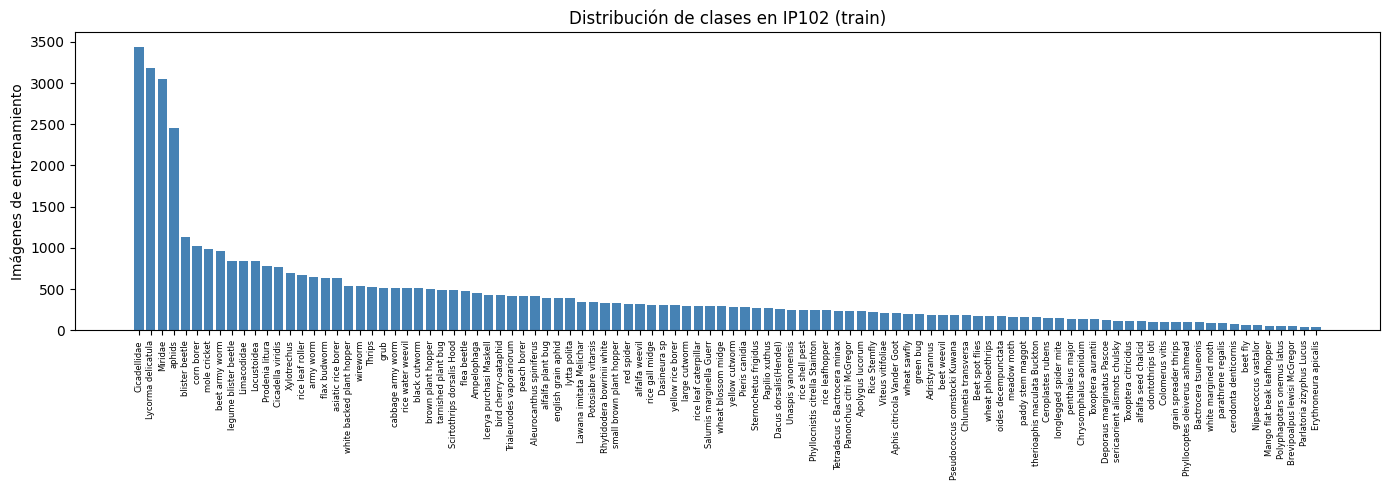

In [18]:
from collections import Counter

train_counts = Counter(y for _, y in train_raw.samples)
val_counts   = Counter(y for _, y in val_raw.samples)
test_counts  = Counter(y for _, y in test_raw.samples)

df_cls = pd.DataFrame({
    "clase": [nombres[i] for i in range(NUM_CLASSES)],
    "n_train": [train_counts[i] for i in range(NUM_CLASSES)],
    "n_val":   [val_counts.get(i, 0) for i in range(NUM_CLASSES)],
    "n_test":  [test_counts.get(i, 0) for i in range(NUM_CLASSES)],
})
print(df_cls.describe())
print(f"\nRazón max/min en train: {df_cls['n_train'].max() / df_cls['n_train'].min():.1f}:1")

orden = df_cls.sort_values("n_train", ascending=False)
plt.figure(figsize=(14, 5))
plt.bar(orden["clase"], orden["n_train"], color="steelblue")
plt.xticks(rotation=90, fontsize=6)
plt.ylabel("Imágenes de entrenamiento")
plt.title("Distribución de clases en IP102 (train)")
plt.tight_layout(); plt.show()

In [19]:
# Corruptas + duplicados + fuga, en UNA lectura por imagen y en paralelo. Resultado en caché (Drive).
LIMPIEZA_JSON = f"{BASE_DIR}/limpieza.json"

def revisar(path_img):
    with open(path_img, "rb") as f:
        datos = f.read()
    h = hashlib.md5(datos).hexdigest()
    try:
        Image.open(io.BytesIO(datos)).verify()
        ok = True
    except Exception:
        ok = False
    return h, ok

def revisar_particion(samples, desc):
    rutas = [p for p, _ in samples]
    with ThreadPoolExecutor(8) as ex:
        res = list(tqdm(ex.map(revisar, rutas), total=len(rutas), desc=desc))
    return [h for h, _ in res], [i for i, (_, ok) in enumerate(res) if not ok]

L = None
if os.path.exists(LIMPIEZA_JSON):
    L = json.load(open(LIMPIEZA_JSON))
    if L.get("n_train_original") != len(train_raw):
        L = None                     # el dataset cambió: recalcular
    else:
        print("Limpieza cargada desde Drive (no se vuelve a calcular)")

if L is None:
    h_tr, mal_tr = revisar_particion(train_raw.samples, "train")
    h_va, mal_va = revisar_particion(val_raw.samples, "val")
    h_te, mal_te = revisar_particion(test_raw.samples, "test")
    s_tr, s_va, s_te = set(h_tr), set(h_va), set(h_te)

    malas, vistos, indices_limpios = set(mal_tr), set(), []
    for i, h in enumerate(h_tr):
        if i in malas or h in vistos or h in s_va or h in s_te:
            continue
        vistos.add(h)
        indices_limpios.append(i)

    L = dict(
        n_train_original=len(h_tr),
        corruptas=dict(train=len(mal_tr), val=len(mal_va), test=len(mal_te)),
        duplicados=dict(train=len(h_tr) - len(s_tr), val=len(h_va) - len(s_va), test=len(h_te) - len(s_te)),
        interseccion=dict(train_val=len(s_tr & s_va), train_test=len(s_tr & s_te), val_test=len(s_va & s_te)),
        indices_limpios=indices_limpios,
    )
    json.dump(L, open(LIMPIEZA_JSON, "w"))

indices_limpios = L["indices_limpios"]
print("Imágenes corruptas:", L["corruptas"])
print("Duplicados dentro de cada partición:", L["duplicados"])
print("Intersecciones entre particiones:", L["interseccion"])
print(f"Train original: {L['n_train_original']} -> limpio: {len(indices_limpios)} "
      f"({L['n_train_original'] - len(indices_limpios)} eliminadas)")

Limpieza cargada desde Drive (no se vuelve a calcular)
Imágenes corruptas: {'train': 0, 'val': 0, 'test': 0}
Duplicados dentro de cada partición: {'train': 3, 'val': 0, 'test': 0}
Intersecciones entre particiones: {'train_val': 0, 'train_test': 2, 'val_test': 0}
Train original: 45095 -> limpio: 45090 (5 eliminadas)


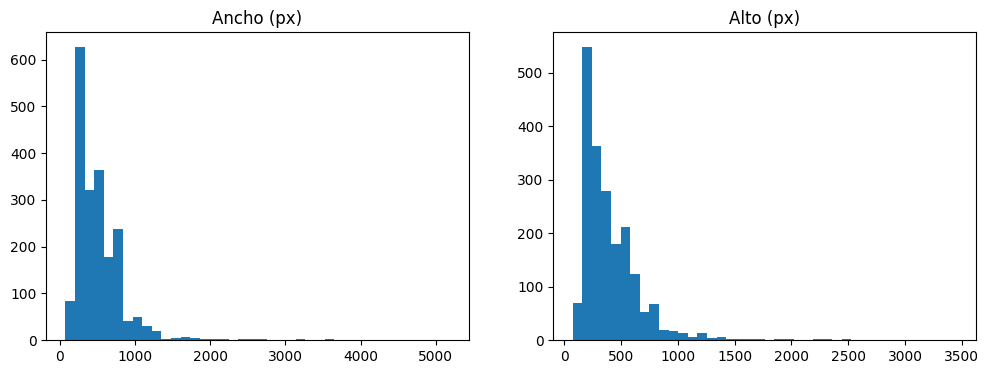

Ancho medio/min/max: 531 / 75 / 5184


In [20]:
# Dimensiones (muestra)
muestra = random.sample(train_raw.samples, 2000)
dims = np.array([Image.open(p).size for p, _ in muestra])

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1); plt.hist(dims[:, 0], bins=40); plt.title("Ancho (px)")
plt.subplot(1, 2, 2); plt.hist(dims[:, 1], bins=40); plt.title("Alto (px)")
plt.show()
print(f"Ancho medio/min/max: {dims[:,0].mean():.0f} / {dims[:,0].min()} / {dims[:,0].max()}")

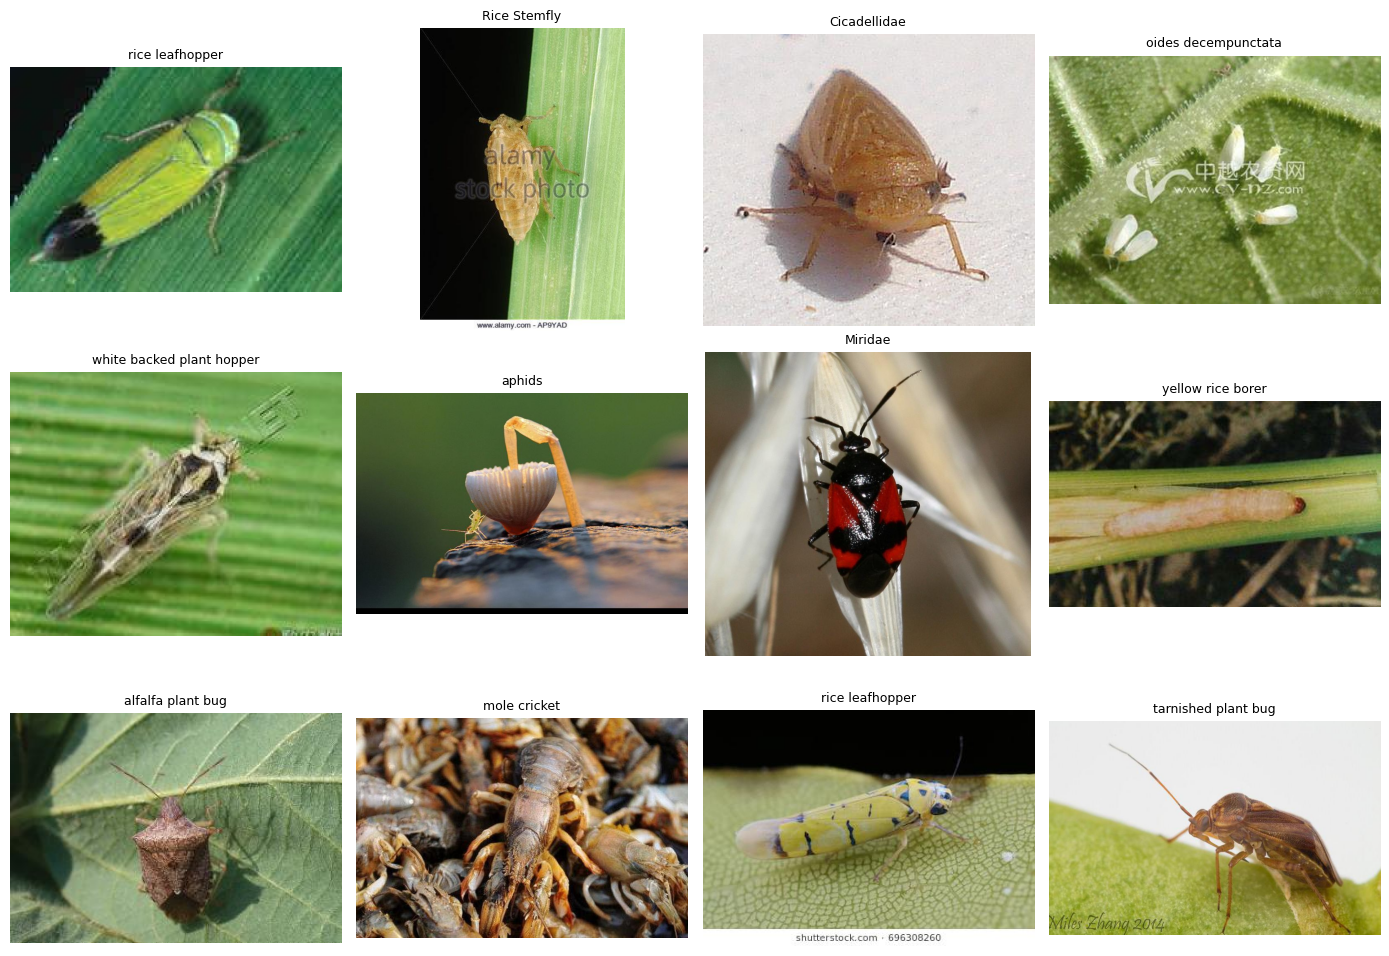

In [21]:
fig, axs = plt.subplots(3, 4, figsize=(14, 10))
for ax, (p, y) in zip(axs.flat, random.sample(train_raw.samples, 12)):
    ax.imshow(Image.open(p).convert("RGB"))
    ax.set_title(nombres[y], fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5. DataLoaders, pesos de clase y velocidad de carga

**Pesos de clase:** raíz del inverso de la frecuencia (más estable que el inverso puro), con razón de desbalance ~82:1.

**Para medir la brecha de sobreajuste** se separa un subconjunto fijo de 5,000 imágenes de train limpio que se evalúa **sin aumentos** en cada época. Medirla con las imágenes aumentadas (o con Mixup) la haría parecer menor de lo que es.



In [22]:
REDUCIR_IMAGENES = False     # ver la celda de diagnóstico más abajo
LADO_CORTO = 320

if REDUCIR_IMAGENES:
    DST = "/content/ip102_small"

    def _reducir(src):
        dst = os.path.join(DST, os.path.relpath(src, correct_path))
        if os.path.exists(dst):
            return
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        with Image.open(src) as im:
            im = im.convert("RGB")
            w, h = im.size
            s = LADO_CORTO / min(w, h)
            if s < 1:
                im = im.resize((round(w * s), round(h * s)), Image.BILINEAR)
            im.save(dst, quality=95)

    rutas = [p for ds_ in (train_raw, val_raw, test_raw) for p, _ in ds_.samples]
    with ThreadPoolExecutor(8) as ex:
        list(tqdm(ex.map(_reducir, rutas), total=len(rutas), desc="reduciendo"))
    train_dir = os.path.join(DST, os.path.relpath(train_dir, correct_path))
    val_dir   = os.path.join(DST, os.path.relpath(val_dir, correct_path))
    test_dir  = os.path.join(DST, os.path.relpath(test_dir, correct_path))
    print("Usando imágenes reducidas en", DST)

In [23]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
val_dataset   = datasets.ImageFolder(val_dir,   transform=eval_transform)
test_dataset  = datasets.ImageFolder(test_dir,  transform=eval_transform)
assert train_dataset.classes == train_raw.classes and len(train_dataset) == len(train_raw)

train_clean = Subset(train_dataset, indices_limpios)
train_targets = np.array([train_dataset.targets[i] for i in indices_limpios])
counts = np.bincount(train_targets, minlength=NUM_CLASSES)
print(f"Imágenes por clase (train limpio): min={counts.min()}, max={counts.max()}, "
      f"razón={counts.max() / counts.min():.1f}:1")

inv_sqrt = 1.0 / np.sqrt(counts.astype(float))
class_weights = torch.tensor(inv_sqrt / inv_sqrt.mean(), dtype=torch.float32).to(device)
print(f"Peso mínimo={class_weights.min():.2f}, máximo={class_weights.max():.2f}")

# Clases pequeñas (para el F1 de cola) y subconjunto de train SIN aumentos (para la brecha)
clases_cola = np.where(counts < CFG["tail_umbral"])[0]
print(f"Clases pequeñas (< {CFG['tail_umbral']} imágenes): {len(clases_cola)} de {NUM_CLASSES}")

rng = np.random.RandomState(SEED)
n_sub = min(CFG["n_train_eval"], len(indices_limpios))
idx_sub = rng.choice(len(indices_limpios), size=n_sub, replace=False)
train_eval_ds = Subset(datasets.ImageFolder(train_dir, transform=eval_transform),
                       [indices_limpios[i] for i in idx_sub])

kw = dict(batch_size=CFG["batch_size"], num_workers=CFG["num_workers"], pin_memory=True)
pw = dict(persistent_workers=True) if CFG["num_workers"] > 0 else {}
train_loader      = DataLoader(train_clean,   shuffle=True,  drop_last=True, **kw, **pw)
val_loader        = DataLoader(val_dataset,   shuffle=False, **kw, **pw)
train_eval_loader = DataLoader(train_eval_ds, shuffle=False, **kw)
test_loader       = DataLoader(test_dataset,  shuffle=False, **kw)
print(f"DataLoaders listos ({CFG['num_workers']} workers). Subconjunto sin aumentos: {n_sub} imágenes.")

Imágenes por clase (train limpio): min=42, max=3444, razón=82.0:1
Peso mínimo=0.26, máximo=2.35
Clases pequeñas (< 200 imágenes): 35 de 102
DataLoaders listos (4 workers). Subconjunto sin aumentos: 5000 imágenes.


## 6. Modelo, entrenamiento y selección del mejor modelo

### Cómo se elige el mejor modelo
En cada época se calcula un **score** que combina tres cosas:

**score = 0.70 · F1_val + 0.15 · F1_cola + 0.15 · (1 − brecha⁺)**

- **F1_val:** F1 macro en validación (la métrica principal).
- **F1_cola:** F1 macro en validación solo sobre las clases pequeñas, donde el desbalance duele más.
- **brecha⁺ = máx(0, F1_train_limpio − F1_val):** castiga el sobreajuste. Se mide con train **sin aumentos**, y solo cuenta cuando es positiva.

**Cuidados:** los pesos son una decisión de diseño y deben fijarse antes de ver los resultados. Si la brecha pesara demasiado, ganarían épocas tempranas con poco ajuste (brecha pequeña, pero F1 bajo). La sección 8 incluye un análisis de sensibilidad para comprobar que el modelo elegido no depende de esos pesos. **El test no participa en la selección.**

### Reanudación y parada temprana
- Cada época se guarda el último estado en Drive (de forma atómica, para no corromper archivos si Colab se corta).
- Al volver a ejecutar un experimento: si ya terminó, se carga su historial; si quedó a medias y la configuración es idéntica, **reanuda desde el último estado**; si la configuración cambió, entrena desde cero.
- Si el score no mejora en `patience` épocas, el entrenamiento se detiene.

In [24]:
class BloqueRes(nn.Module):
    """Bloque residual: dos convoluciones 3x3 con BatchNorm y una conexión de atajo (suma)."""
    def __init__(self, c_in, c_out, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.atajo = None
        if stride != 1 or c_in != c_out:          # el atajo ajusta forma si cambian canales o tamaño
            self.atajo = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride, bias=False),
                                       nn.BatchNorm2d(c_out))

    def forward(self, x):
        y = F.relu(self.bn1(self.conv1(x)), inplace=True)
        y = self.bn2(self.conv2(y))
        return F.relu(y + (x if self.atajo is None else self.atajo(x)))


class PlagasNet(nn.Module):
    """CNN residual diseñada desde cero (sin pesos preentrenados), ~2.8 M de parámetros."""
    def __init__(self, num_classes=102, anchos=(32, 64, 128, 256), bloques=(2, 2, 2, 2), dropout=0.3):
        super().__init__()
        # Stem: reduce 224x224 a 56x56 con dos convoluciones de paso 2
        self.stem = nn.Sequential(
            nn.Conv2d(3, 24, 3, 2, 1, bias=False), nn.BatchNorm2d(24), nn.ReLU(inplace=True),
            nn.Conv2d(24, anchos[0], 3, 2, 1, bias=False), nn.BatchNorm2d(anchos[0]), nn.ReLU(inplace=True),
        )
        capas, c_in = [], anchos[0]
        for i, (c, n) in enumerate(zip(anchos, bloques)):
            for j in range(n):
                capas.append(BloqueRes(c_in, c, stride=2 if (j == 0 and i > 0) else 1))
                c_in = c
        self.cuerpo = nn.Sequential(*capas)          # 56x56 -> 28x28 -> 14x14 -> 7x7
        self.cabeza = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                    nn.Dropout(dropout), nn.Linear(c_in, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
        for m in self.modules():
            if isinstance(m, BloqueRes):
                nn.init.zeros_(m.bn2.weight)         # cada bloque empieza como identidad: entrena más estable

    def forward(self, x):
        return self.cabeza(self.cuerpo(self.stem(x)))


def build_model(name="convnext_tiny", drop_path=0.1, pretrained=True):
    if name == "plagasnet":                           # arquitectura propia (drop_path = dropout de la cabeza)
        return PlagasNet(NUM_CLASSES, dropout=drop_path)
    return timm.create_model(name, pretrained=pretrained, num_classes=NUM_CLASSES,
                             drop_path_rate=drop_path)


class WeightedSoftTargetCE(nn.Module):
    """Cross-entropy con pesos de clase y soporte para soft targets (Mixup/CutMix)."""
    def __init__(self, class_weights=None):
        super().__init__()
        self.register_buffer("class_weights", class_weights)

    def forward(self, logits, targets):
        if targets.ndim == 1:
            return F.cross_entropy(logits, targets, weight=self.class_weights)
        log_probs = F.log_softmax(logits, dim=1)
        if self.class_weights is not None:
            log_probs = log_probs * self.class_weights.unsqueeze(0)
        return -(targets * log_probs).sum(dim=1).mean()


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    """Devuelve loss (sin pesos si se da criterion), acc, F1 macro, predicciones y etiquetas."""
    model.eval()
    preds_all, labels_all, running = [], [], 0.0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            outputs = model(images)
            if criterion is not None:
                running += criterion(outputs, labels).item() * images.size(0)
        preds_all.append(outputs.argmax(1).cpu().numpy())
        labels_all.append(labels.cpu().numpy())
    preds = np.concatenate(preds_all)
    labels = np.concatenate(labels_all)
    return dict(
        loss=(running / len(loader.dataset)) if criterion is not None else None,
        acc=accuracy_score(labels, preds),
        f1=f1_score(labels, preds, average="macro"),
        preds=preds, labels=labels,
    )


def calcular_score(f1_val, f1_cola, gap, w=None):
    w = w or (CFG["w_f1"], CFG["w_cola"], CFG["w_gap"])
    return w[0] * f1_val + w[1] * f1_cola + w[2] * (1.0 - gap)


def decidir_accion(ck, cfg, epochs, patience):
    """'nuevo' | 'reanudar' | 'completo' | 'cfg_distinta', decidido SOLO con el último checkpoint."""
    if ck is None:
        return "nuevo"
    if ck.get("cfg") != cfg:
        return "cfg_distinta"
    if ck["epoch"] >= epochs or ck["sin_mejora"] >= patience:
        return "completo"
    return "reanudar"


def guardar(obj, path):
    """Guarda de forma atómica: si Colab se corta a mitad, el archivo anterior sigue intacto."""
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def sincronizar_drive():
    t0 = time.time()
    if os.path.exists("/kaggle/working"):
        res = os.system("rclone copy /kaggle/working/ip102 gdrive:ip102")
        if res == 0:
            print(f"   Drive sincronizado vía rclone ({time.time() - t0:.0f}s)")
        else:
            print("   (aviso) error al sincronizar con rclone")
        return
    if not BASE_DIR.startswith("/content/drive"):
        return
    try:
        from google.colab import drive
        drive.flush_and_unmount()
        drive.mount("/content/drive")
        print(f"   Drive sincronizado ({time.time() - t0:.0f}s)")
    except Exception as e:
        print(f"   (aviso) no se pudo sincronizar Drive: {e}")



HIST_KEYS = ["train_loss", "train_acc", "train_f1", "val_loss", "val_acc", "val_f1",
             "val_f1_cola", "train_f1_limpio", "brecha", "score", "lr"]
histories = {}

In [25]:
def run_experiment(name, model_name="convnext_tiny", use_weights=True, label_smoothing=0.1,
                   drop_path=0.1, epochs=None, lr=None, mixup=False, resume=True, patience=None,
                   weight_decay=None):
    epochs = epochs or CFG["epochs"]
    lr = lr or CFG["lr"]
    patience = patience or CFG["patience"]
    cfg_saved = dict(model_name=model_name, use_weights=use_weights, label_smoothing=label_smoothing,
                     drop_path=drop_path, epochs=epochs, lr=lr, mixup=mixup,
                     w_score=[CFG["w_f1"], CFG["w_cola"], CFG["w_gap"]])
    if weight_decay is not None:             # solo entra en la cfg si se pide: no invalida checkpoints viejos
        cfg_saved["weight_decay"] = weight_decay
    last_path = f"{CKPT_DIR}/{name}_last.pth"
    best_path = f"{CKPT_DIR}/{name}_best.pth"
    meta_path = f"{CKPT_DIR}/{name}_meta.json"

    ck = None
    if resume and os.path.exists(last_path):
        try:
            ck = torch.load(last_path, map_location="cpu", weights_only=False)
        except Exception as e:
            print(f"No se pudo leer {last_path} ({e}); se entrena desde cero.")
    accion = decidir_accion(ck, cfg_saved, epochs, patience) if resume else "nuevo"
    if accion == "completo":
        print(f"'{name}' ya está entrenado (última época {ck['epoch']}, mejor época {ck['best_epoch']}); "
              f"se carga su historial.")
        histories[name] = ck["history"]
        return ck["best_score"]
    if accion == "cfg_distinta":
        print(f"'{name}': la configuración cambió respecto a la guardada; se entrena desde cero.")

    set_seed()
    base_model = build_model(model_name, drop_path).to(device)
    fwd = base_model
    if CFG["use_compile"]:
        try:
            fwd = torch.compile(base_model)
        except Exception as e:
            print("torch.compile no disponible, modo estándar:", e)

    if mixup:
        mixup_fn = Mixup(mixup_alpha=0.2, cutmix_alpha=1.0, prob=0.5, switch_prob=0.5,
                         label_smoothing=label_smoothing, num_classes=NUM_CLASSES)
        criterion_train = WeightedSoftTargetCE(class_weights if use_weights else None)
    else:
        mixup_fn = None
        criterion_train = nn.CrossEntropyLoss(weight=class_weights if use_weights else None,
                                              label_smoothing=label_smoothing)
    criterion_val = nn.CrossEntropyLoss()      # sin pesos ni smoothing: comparable entre experimentos

    optimizer = torch.optim.AdamW(base_model.parameters(), lr=lr,
                                  weight_decay=weight_decay if weight_decay is not None else CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    history = {k: [] for k in HIST_KEYS}
    best_score, best_epoch, sin_mejora, start_epoch = -1.0, 0, 0, 1

    if accion == "reanudar":
        base_model.load_state_dict(ck["state_dict"])
        optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"])
        scaler.load_state_dict(ck["scaler"])
        history, best_score = ck["history"], ck["best_score"]
        best_epoch, sin_mejora, start_epoch = ck["best_epoch"], ck["sin_mejora"], ck["epoch"] + 1
        print(f"Reanudando '{name}' desde la época {start_epoch}")
        del ck

    print(f"\n===== Experimento: {name} | {cfg_saved} =====")

    def escribir_meta(done):
        # Copia legible del estado. NO se usa para decidir nada: la fuente de verdad es {name}_last.pth
        try:
            tmp = meta_path + ".tmp"
            with open(tmp, "w") as f:
                json.dump(dict(cfg=cfg_saved, done=done, history=history, best_epoch=best_epoch,
                               best_score=best_score, sin_mejora=sin_mejora), f)
                f.flush(); os.fsync(f.fileno())
            os.replace(tmp, meta_path)
        except Exception as e:
            print(f"   (aviso) no se pudo escribir {meta_path}: {e}")

    for epoch in range(start_epoch, epochs + 1):
        t0 = time.time()
        fwd.train()
        running, preds_all, labels_all = 0.0, [], []
        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            labels_orig = labels
            if mixup_fn is not None:
                images, labels = mixup_fn(images, labels)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                outputs = fwd(images)
                loss = criterion_train(outputs, labels)
            scaler.scale(loss).backward()
            if CFG["grad_clip"]:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(base_model.parameters(), CFG["grad_clip"])
            scaler.step(optimizer)
            scaler.update()

            running += loss.item() * images.size(0)
            preds_all.append(outputs.argmax(1).cpu().numpy())
            labels_all.append(labels_orig.cpu().numpy())
        t_train = time.time() - t0

        p, l = np.concatenate(preds_all), np.concatenate(labels_all)
        v = evaluate(fwd, val_loader, criterion_val)
        tr = evaluate(fwd, train_eval_loader)            # train limpio, sin aumentos
        f1_cola = float(f1_score(v["labels"], v["preds"], labels=clases_cola,
                                 average="macro", zero_division=0))
        gap = max(0.0, float(tr["f1"] - v["f1"]))
        score = float(calcular_score(float(v["f1"]), f1_cola, gap))

        for k, val in dict(train_loss=running / len(train_loader.dataset),
                           train_acc=accuracy_score(l, p), train_f1=f1_score(l, p, average="macro"),
                           val_loss=v["loss"], val_acc=v["acc"], val_f1=v["f1"],
                           val_f1_cola=f1_cola, train_f1_limpio=tr["f1"], brecha=gap,
                           score=score, lr=optimizer.param_groups[0]["lr"]).items():
            history[k].append(float(val))
        scheduler.step()

        is_best = score > best_score
        if is_best:
            best_score, best_epoch, sin_mejora = score, epoch, 0
            guardar(dict(epoch=epoch, state_dict=base_model.state_dict(), cfg=cfg_saved,
                         val_f1=float(v["f1"]), val_f1_cola=f1_cola, brecha=gap, score=score), best_path)
        else:
            sin_mejora += 1
        guardar(dict(epoch=epoch, state_dict=base_model.state_dict(), optimizer=optimizer.state_dict(),
                     scheduler=scheduler.state_dict(), scaler=scaler.state_dict(), history=history,
                     best_score=best_score, best_epoch=best_epoch, sin_mejora=sin_mejora,
                     cfg=cfg_saved), last_path)
        escribir_meta(done=False)

        print(f"Ép {epoch:>2}/{epochs} | train_f1 {history['train_f1'][-1]:.3f} | "
              f"val loss {v['loss']:.3f} acc {v['acc']:.3f} F1 {v['f1']:.3f} cola {f1_cola:.3f} | "
              f"brecha {gap:.3f} | score {score:.4f}{' ★' if is_best else ''} | "
              f"{time.time() - t0:.0f}s (train {t_train:.0f}s) | "
              f"guardado: última época {epoch}, {os.path.getsize(last_path) / 1e6:.0f} MB")
        if CFG["sync_cada"] and epoch % CFG["sync_cada"] == 0:
            sincronizar_drive()
        if sin_mejora >= patience:
            print(f"Parada temprana: {patience} épocas sin mejorar el score (mejor: época {best_epoch}).")
            break

    escribir_meta(done=True)
    if CFG["sync_cada"]:
        sincronizar_drive()
    histories[name] = history
    return best_score


def plot_history(h, title=""):
    ep = range(1, len(h["val_f1"]) + 1)
    mejor = int(np.argmax(h["score"])) + 1
    fig, axs = plt.subplots(1, 4, figsize=(22, 4))
    axs[0].plot(ep, h["train_loss"], "o-", label="Train (con aumentos)")
    axs[0].plot(ep, h["val_loss"], "o-", label="Validación")
    axs[0].set_title("Pérdida")
    axs[1].plot(ep, h["train_acc"], "o-", label="Train (con aumentos)")
    axs[1].plot(ep, h["val_acc"], "o-", label="Validación")
    axs[1].axhline(0.70, color="g", ls="--", label="Meta (70%)")
    axs[1].set_title("Accuracy")
    axs[2].plot(ep, h["train_f1_limpio"], "o-", label="Train limpio")
    axs[2].plot(ep, h["val_f1"], "o-", label="Validación")
    axs[2].plot(ep, h["val_f1_cola"], "o--", label="Validación, clases pequeñas")
    axs[2].set_title("F1 macro")
    axs[3].plot(ep, h["score"], "o-", color="purple", label="Score")
    axs[3].plot(ep, h["brecha"], "o-", color="red", label="Brecha F1 (train limpio − val)")
    axs[3].set_title("Score y brecha")
    for ax in axs:
        ax.axvline(mejor, color="gray", ls=":", label=f"Mejor época por score ({mejor})")
        ax.set_xlabel("Época"); ax.grid(ls="--", alpha=.4); ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

In [26]:
import os
import torch

# Verificar qué archivos hay físicamente en la ruta de checkpoints
print("Contenido actual en CKPT_DIR:", CKPT_DIR)
if os.path.exists(CKPT_DIR):
    archivos = os.listdir(CKPT_DIR)
    for f in sorted(archivos):
        ruta_completa = os.path.join(CKPT_DIR, f)
        tamaño_mb = os.path.getsize(ruta_completa) / 1e6
        print(f" - {f} ({tamaño_mb:.2f} MB)")
else:
    print("La carpeta de checkpoints no existe o no está accesible.")

Contenido actual en CKPT_DIR: /kaggle/working/ip102/checkpoints
 - A_base_best.pth (111.67 MB)
 - A_base_last.pth (335.01 MB)
 - A_base_meta.json (0.00 MB)
 - B_pesos_best.pth (111.67 MB)
 - B_pesos_last.pth (335.01 MB)
 - B_pesos_meta.json (0.00 MB)
 - C_pesos_reg_best.pth (111.67 MB)
 - C_pesos_reg_last.pth (335.02 MB)
 - C_pesos_reg_meta.json (0.00 MB)
 - D_resnet50_best.pth (95.19 MB)
 - D_resnet50_last.pth (285.08 MB)
 - D_resnet50_meta.json (0.01 MB)
 - F_mix_suave_best.pth (111.67 MB)
 - F_mix_suave_last.pth (335.02 MB)
 - F_mix_suave_meta.json (0.01 MB)
 - G_cnn_scratch_best.pth (11.38 MB)
 - G_cnn_scratch_last.pth (34.06 MB)
 - G_cnn_scratch_meta.json (0.01 MB)


## 7. Experimentos

Cada experimento cambia pocas cosas respecto al anterior, para poder atribuir mejoras:

| Nombre | Pesos de clase | Label smoothing | Drop path | Mixup/CutMix | LR | Épocas |
|---|---|---|---|---|---|---|
| `A_base` | No | 0 | 0 | No | 5e-5 | 9 |
| `B_pesos` | Sí | 0 | 0 | No | 5e-5 | 9 |
| `C_pesos_reg` | Sí | 0.1 | 0.1 | No | 5e-5 | 12 |
| `F_mix_suave` | Sí | 0.1 | 0.1 | Sí | 1e-4 | 15 |
| `D_resnet50` (opcional) | Sí | 0.1 | 0.05 | No | 5e-5 | 9 |
| `G_cnn_scratch` (arquitectura propia, sin preentrenar) | Sí | 0.1 | dropout 0.3 | No | 1e-3 | 25 |

**Presupuesto de épocas distinto.** C y F reciben más épocas porque en la corrida anterior su mejor resultado ocurrió en la última época. Eso significa que **no es una comparación a igual presupuesto**. Para comparar todos con las mismas épocas, pon `EPOCAS_FORZADAS = 12` (o el valor que prefieras). La parada temprana evita gastar épocas de más.

**Varias sesiones.** Si Colab se corta, vuelve a ejecutar la celda: lo terminado se salta y lo que quedó a medias se reanuda. Los experimentos van ordenados por prioridad. Si cambias la configuración de uno, se entrena desde cero.

Cada época dura ~7 minutos, así que A+B+C+F pueden sumar varias horas. Corre solo los que necesites en `a_correr`.

In [38]:
 EXPERIMENTS = {
    "A_base":      dict(use_weights=False, label_smoothing=0.0, drop_path=0.0, epochs=25),
    "B_pesos":     dict(use_weights=True,  label_smoothing=0.0, drop_path=0.0, epochs=25),
    "C_pesos_reg": dict(use_weights=True,  label_smoothing=0.1, drop_path=0.1, epochs=25),
    "F_mix_suave": dict(use_weights=True,  label_smoothing=0.1, drop_path=0.1, epochs=25,
                        lr=1e-4, mixup=True),
    "D_resnet50":  dict(model_name="resnet50", use_weights=True, label_smoothing=0.1,
                        drop_path=0.05, epochs=25),
    # Arquitectura propia desde cero: lr y weight decay más altos, más épocas y más paciencia
    "G_cnn_scratch": dict(model_name="plagasnet", use_weights=True, label_smoothing=0.1,
                          drop_path=0.3, epochs=25, lr=1e-3, weight_decay=5e-2, patience=6),
}
a_correr = ["F_mix_suave", "G_cnn_scratch"]   # por prioridad
EPOCAS_FORZADAS = None      # p. ej. 12 para comparar todos con el mismo número de épocas

for nombre in a_correr:
    params = dict(EXPERIMENTS[nombre])
    if EPOCAS_FORZADAS:
        params["epochs"] = EPOCAS_FORZADAS
    run_experiment(nombre, **params)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Reanudando 'F_mix_suave' desde la época 22

===== Experimento: F_mix_suave | {'model_name': 'convnext_tiny', 'use_weights': True, 'label_smoothing': 0.1, 'drop_path': 0.1, 'epochs': 25, 'lr': 0.0001, 'mixup': True, 'w_score': [0.7, 0.15, 0.15]} =====


W1125 23:21:56.732000 50 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


Ép 22/25 | train_f1 0.789 | val loss 1.300 acc 0.745 F1 0.682 cola 0.633 | brecha 0.278 | score 0.6804 | 539s (train 431s) | guardado: última época 22, 335 MB
   Drive sincronizado vía rclone (10s)
Ép 23/25 | train_f1 0.789 | val loss 1.305 acc 0.746 F1 0.682 cola 0.627 | brecha 0.277 | score 0.6796 | 229s (train 191s) | guardado: última época 23, 335 MB
   Drive sincronizado vía rclone (11s)
Ép 24/25 | train_f1 0.791 | val loss 1.313 acc 0.745 F1 0.681 cola 0.633 | brecha 0.279 | score 0.6799 | 229s (train 192s) | guardado: última época 24, 335 MB
   Drive sincronizado vía rclone (11s)
Parada temprana: 4 épocas sin mejorar el score (mejor: época 20).
   Drive sincronizado vía rclone (2s)
'G_cnn_scratch' ya está entrenado (última época 25, mejor época 25); se carga su historial.


### 7.1 Arquitectura propia, desde cero (`PlagasNet`)
Red convolucional residual diseñada para este proyecto y entrenada **sin pesos preentrenados**, para comparar qué tanto aporta el preentrenamiento de ConvNeXt-Tiny.

| Parte | Detalle | Salida |
|---|---|---|
| Entrada | Imagen RGB | 3 × 224 × 224 |
| Stem | Conv 3×3 (paso 2, 24 canales) + BN + ReLU; Conv 3×3 (paso 2, 32 canales) + BN + ReLU | 32 × 56 × 56 |
| Etapa 1 | 2 bloques residuales, 32 canales | 32 × 56 × 56 |
| Etapa 2 | 2 bloques residuales, 64 canales (el primero con paso 2) | 64 × 28 × 28 |
| Etapa 3 | 2 bloques residuales, 128 canales (el primero con paso 2) | 128 × 14 × 14 |
| Etapa 4 | 2 bloques residuales, 256 canales (el primero con paso 2) | 256 × 7 × 7 |
| Cabeza | Pooling promedio global → Dropout 0.3 → Linear(256, 102) | 102 |

Cada **bloque residual** hace Conv 3×3 → BN → ReLU → Conv 3×3 → BN, y le **suma la entrada** (conexión de atajo, con una convolución 1×1 si cambian los canales o el tamaño). Decisiones de diseño:
- **Conexiones residuales:** permiten entrenar desde cero sin que el gradiente se desvanezca.
- **BatchNorm** tras cada convolución: estabiliza el entrenamiento.
- **Pooling global y una sola capa lineal:** menos parámetros que aplanar el mapa final, lo que ayuda con un dataset de ~45,000 imágenes.
- **Inicialización Kaiming**, y el último BN de cada bloque en cero para que cada bloque empiece siendo la identidad.
- **Tamaño:** ~2.8 M de parámetros y ~450 M de MACs por imagen, frente a ~28.6 M de parámetros y ~4.5 G de MACs de ConvNeXt-Tiny.

**Entrenamiento desde cero:** necesita un learning rate más alto (1e-3), más weight decay (5e-2) y más épocas (25, con paciencia 6) que el ajuste fino de un modelo preentrenado. Como la red es ligera, es probable que el cuello de botella sea la carga de imágenes y no la GPU; la celda de diagnóstico de la sección 5 y `REDUCIR_IMAGENES` ayudan a acortar el tiempo. **Espera un desempeño bastante menor que el de ConvNeXt-Tiny preentrenado**: no hay una cifra de referencia aquí; el experimento sirve precisamente para medir esa diferencia.

In [28]:
print(f"PlagasNet: {sum(p.numel() for p in PlagasNet(NUM_CLASSES).parameters()) / 1e6:.2f} M de parámetros")
print(f"ConvNeXt-Tiny: {sum(p.numel() for p in build_model('convnext_tiny', pretrained=False).parameters()) / 1e6:.2f} M de parámetros")

run_experiment("G_cnn_scratch", **EXPERIMENTS["G_cnn_scratch"])

PlagasNet: 2.83 M de parámetros
ConvNeXt-Tiny: 27.90 M de parámetros
'G_cnn_scratch' ya está entrenado (última época 25, mejor época 25); se carga su historial.


0.4483930987486282

### Comprobar que lo guardado en Drive está al día
`{nombre}_last.pth` es la **fuente de verdad** de cada experimento; `{nombre}_meta.json` es solo una copia legible. Esta celda muestra qué hay realmente guardado. Si la época de `last.pth` no coincide con las épocas que viste correr, Drive no sincronizó todo (ver la celda siguiente).

In [29]:
def diagnostico_checkpoints(nombres=None):
    nombres = nombres or sorted({f.split("_last.pth")[0] for f in os.listdir(CKPT_DIR) if f.endswith("_last.pth")})
    for n in nombres:
        print(f"--- {n} ---")
        for suf in ["last.pth", "best.pth", "meta.json"]:
            p = f"{CKPT_DIR}/{n}_{suf}"
            if os.path.exists(p):
                print(f"  {suf:10s} {os.path.getsize(p) / 1e6:7.1f} MB | modificado: {time.ctime(os.path.getmtime(p))}")
            else:
                print(f"  {suf:10s} (no existe)")
        p = f"{CKPT_DIR}/{n}_last.pth"
        if os.path.exists(p):
            c = torch.load(p, map_location="cpu", weights_only=False)
            print(f"  last.pth -> época {c['epoch']} de {c['cfg']['epochs']} | épocas en el historial: "
                  f"{len(c['history']['val_f1'])} | mejor época: {c['best_epoch']} | épocas sin mejora: {c['sin_mejora']}")

diagnostico_checkpoints()

--- A_base ---
  last.pth     335.0 MB | modificado: Wed Nov 25 20:09:14 2026
  best.pth     111.7 MB | modificado: Wed Nov 25 03:03:31 2026
  meta.json      0.0 MB | modificado: Wed Nov 25 20:09:32 2026
  last.pth -> época 15 de 25 | épocas en el historial: 15 | mejor época: 11 | épocas sin mejora: 4
--- B_pesos ---
  last.pth     335.0 MB | modificado: Wed Nov 25 01:12:12 2026
  best.pth     111.7 MB | modificado: Wed Nov 25 00:37:32 2026
  meta.json      0.0 MB | modificado: Wed Nov 25 01:12:42 2026
  last.pth -> época 8 de 25 | épocas en el historial: 8 | mejor época: 4 | épocas sin mejora: 4
--- C_pesos_reg ---
  last.pth     335.0 MB | modificado: Wed Nov 25 16:22:22 2026
  best.pth     111.7 MB | modificado: Wed Nov 25 13:22:34 2026
  meta.json      0.0 MB | modificado: Wed Nov 25 16:22:42 2026
  last.pth -> época 12 de 25 | épocas en el historial: 12 | mejor época: 8 | épocas sin mejora: 4
--- D_resnet50 ---
  last.pth     285.1 MB | modificado: Wed Nov 25 20:19:51 2026
  best.

**Sincronización con Drive.** Colab escribe en Drive de forma diferida: si la sesión se corta antes de que termine de subirse, el archivo en Drive puede quedar en una versión anterior. Por eso `run_experiment` fuerza la subida (desmonta y vuelve a montar Drive) cada `CFG["sync_cada"]` épocas y al terminar. Cada vez imprime cuántos segundos tardó: si es demasiado, sube `sync_cada` a 2 o 3. Esta celda permite hacerlo a mano en cualquier momento.

In [30]:
sincronizar_drive()

   Drive sincronizado vía rclone (1s)


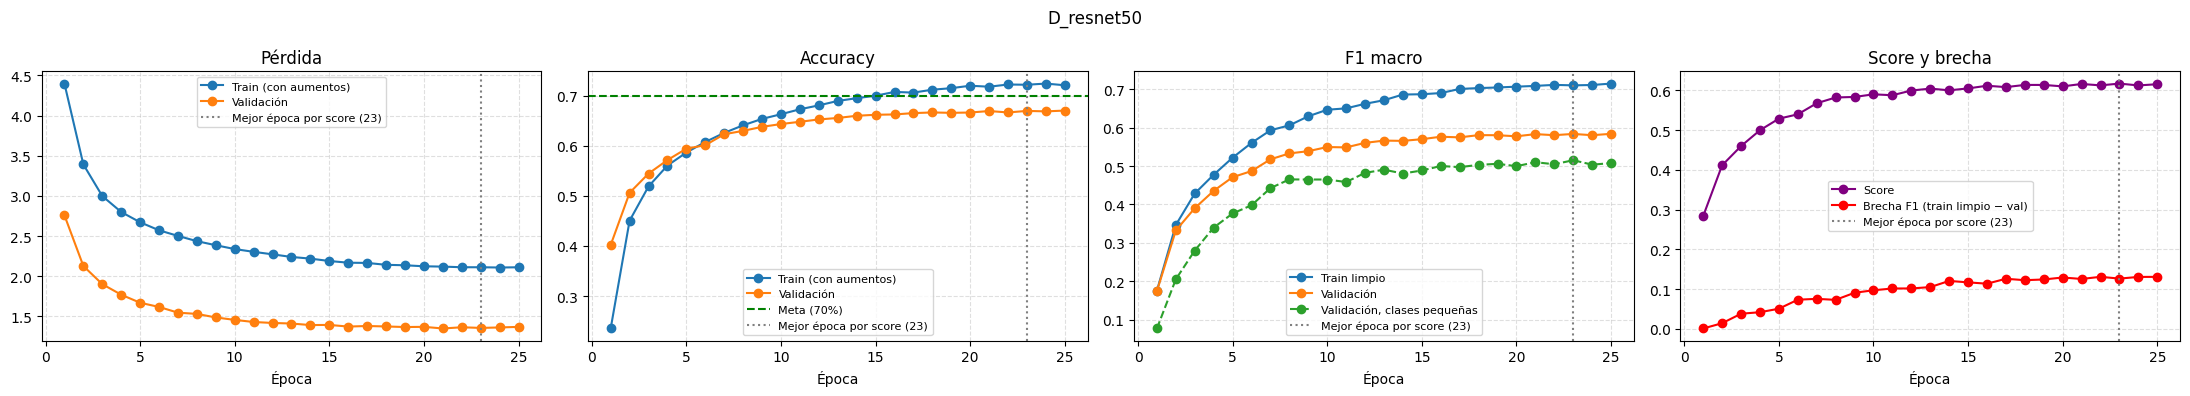

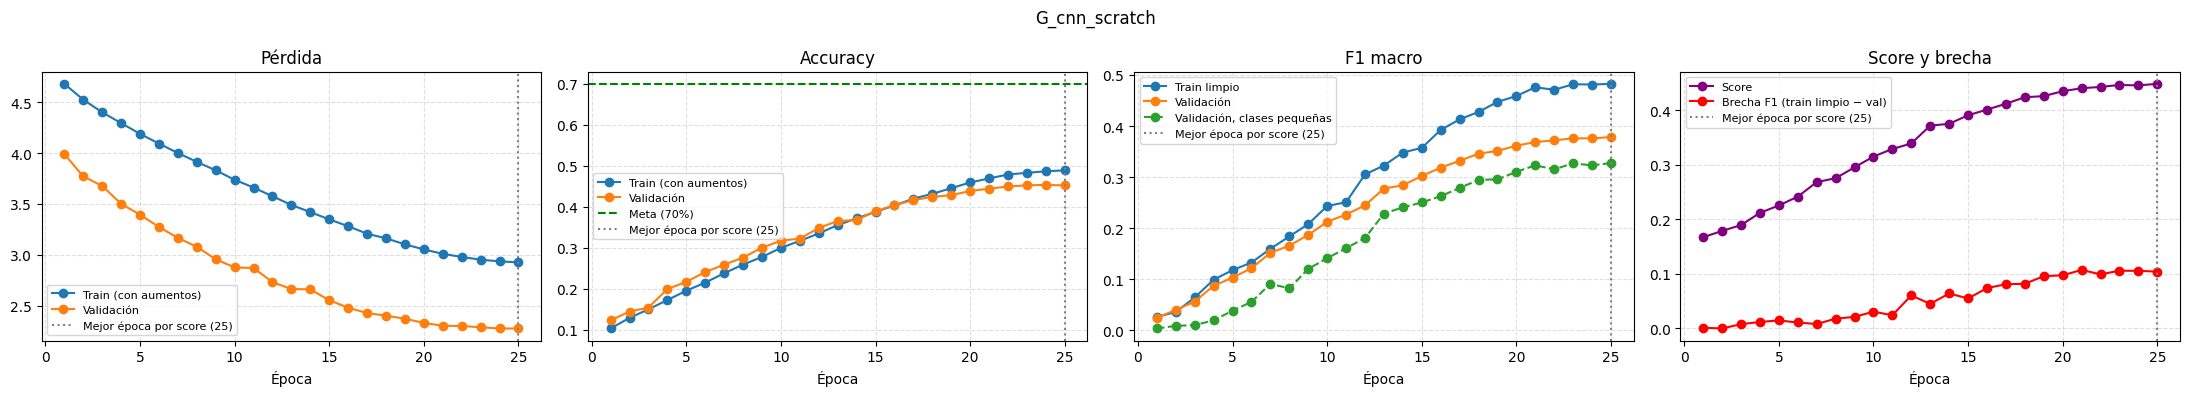

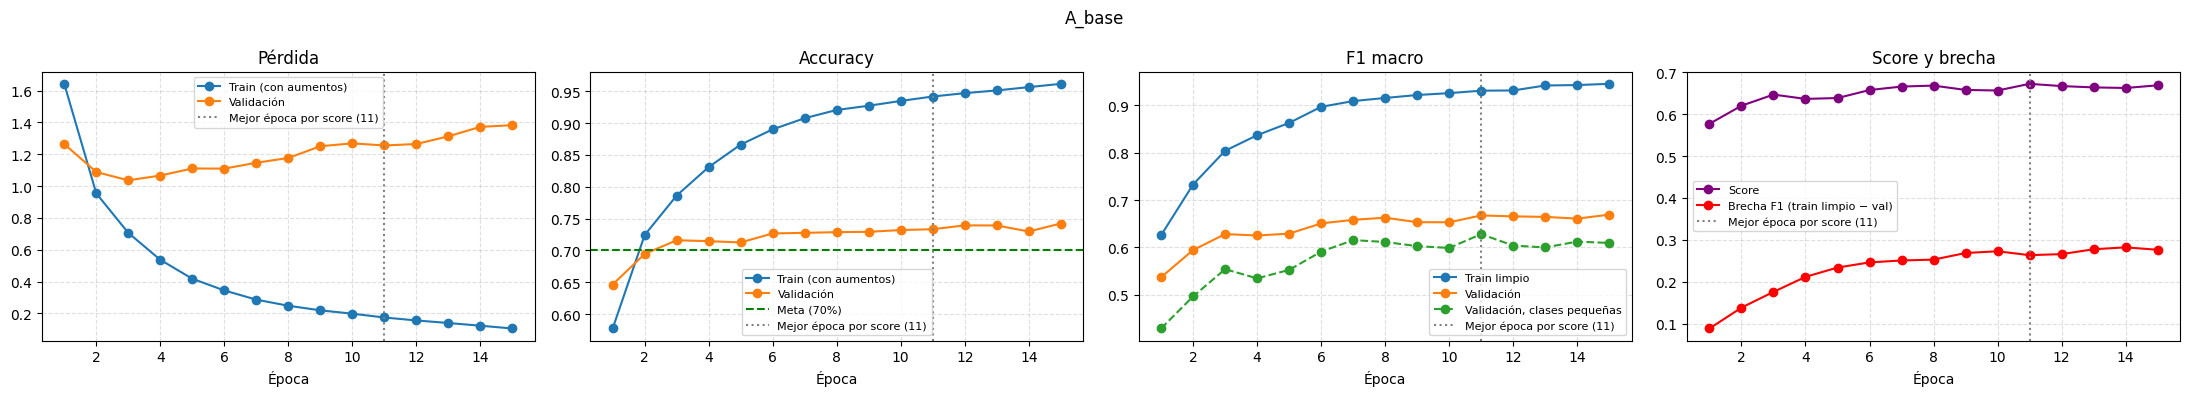

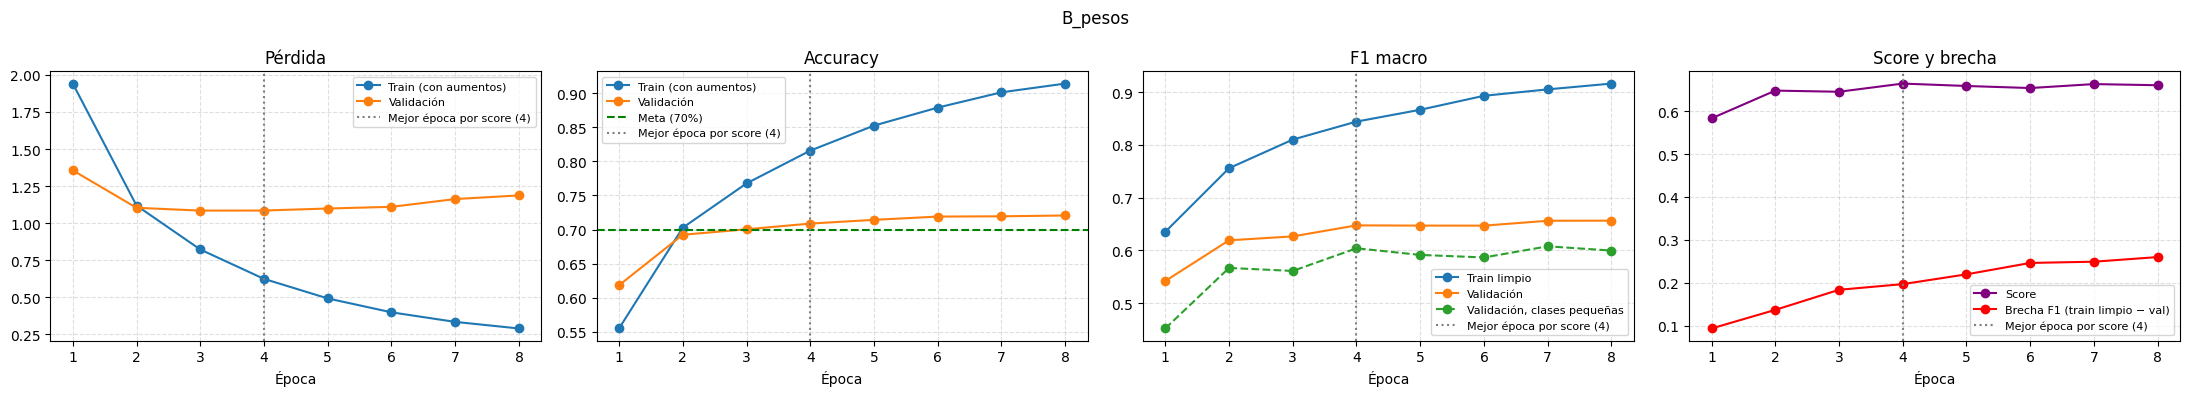

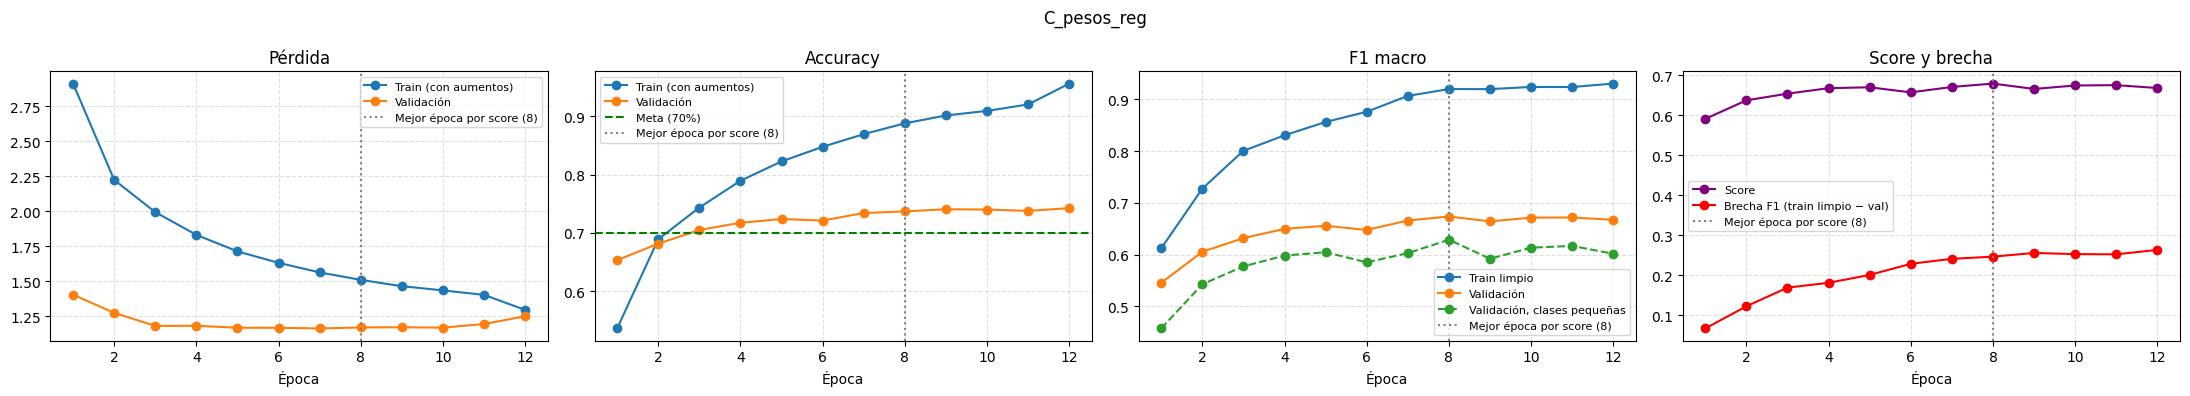

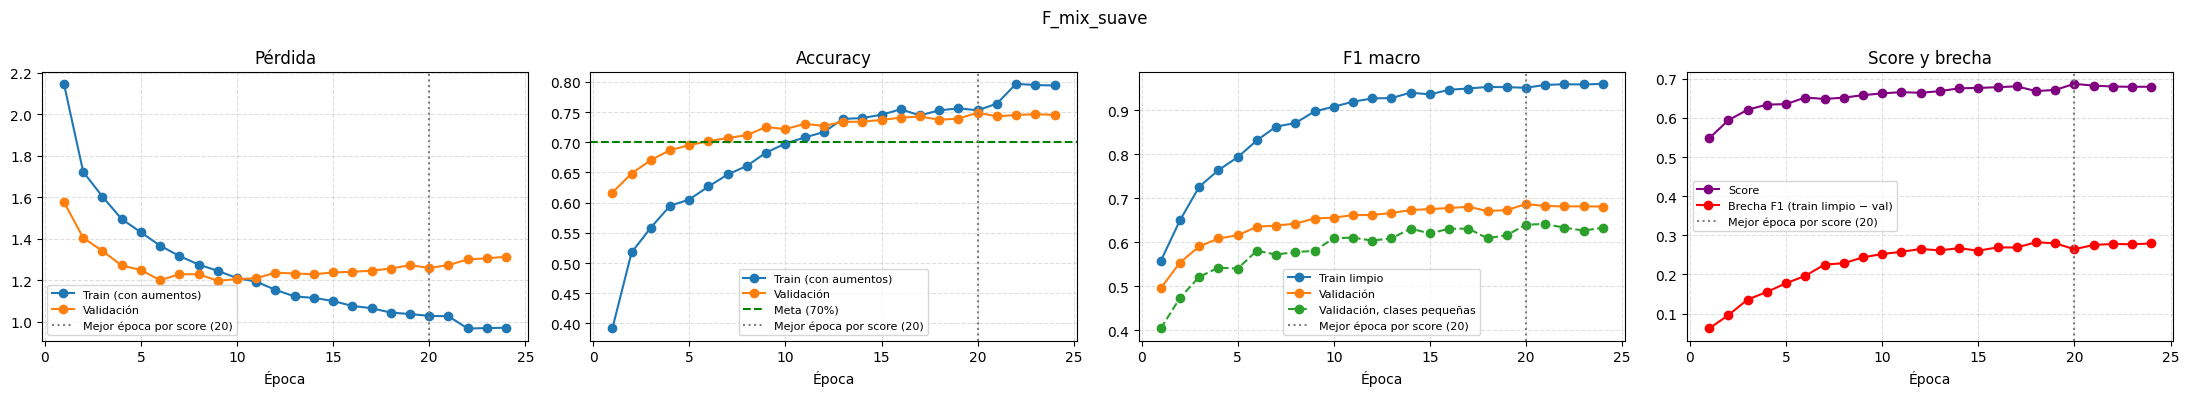

In [39]:
for nombre, h in histories.items():
    plot_history(h, nombre)

Historial de 'A_base' cargado correctamente (15 épocas).
Historial de 'B_pesos' cargado correctamente (8 épocas).
Historial de 'C_pesos_reg' cargado correctamente (12 épocas).
Historial de 'F_mix_suave' cargado correctamente (24 épocas).
Historial de 'G_cnn_scratch' cargado correctamente (25 épocas).


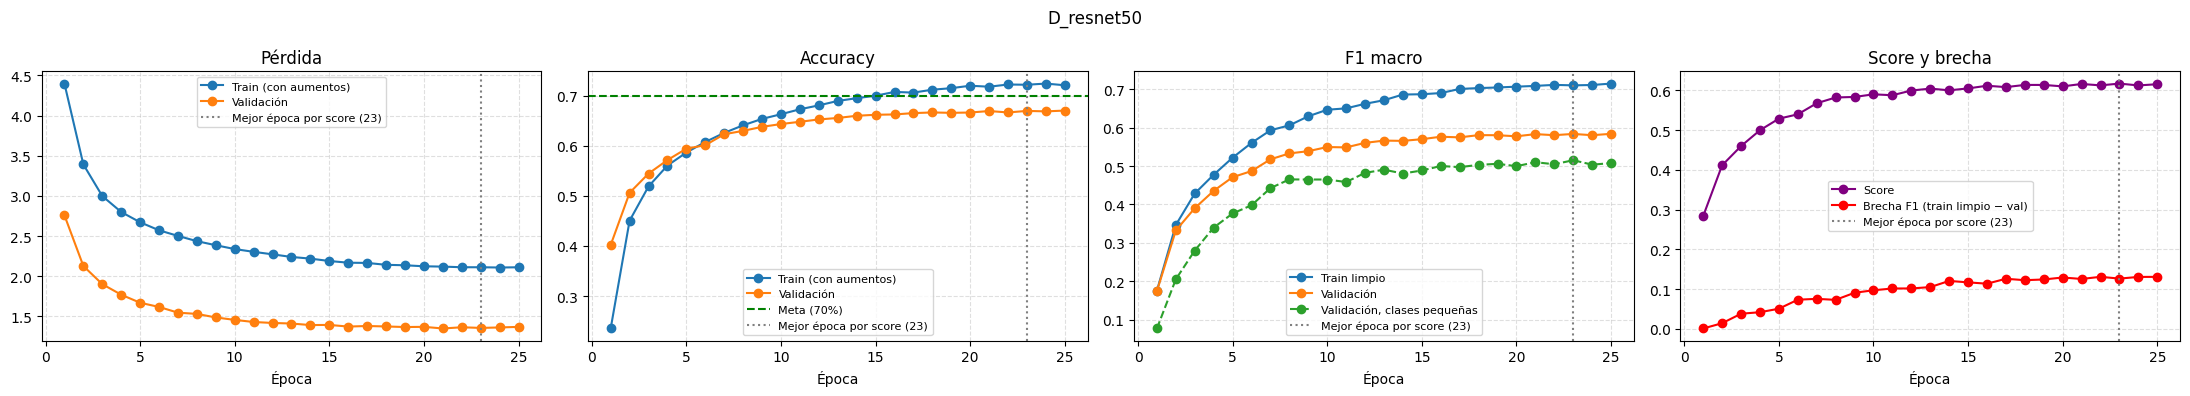

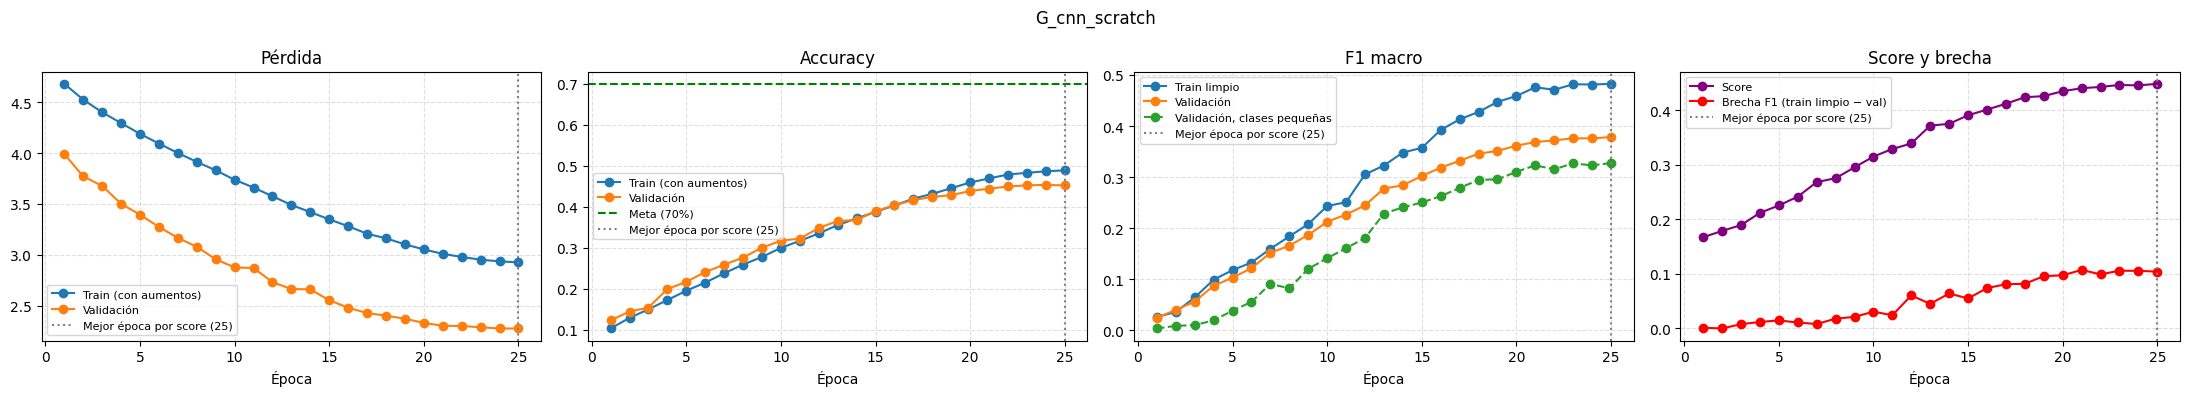

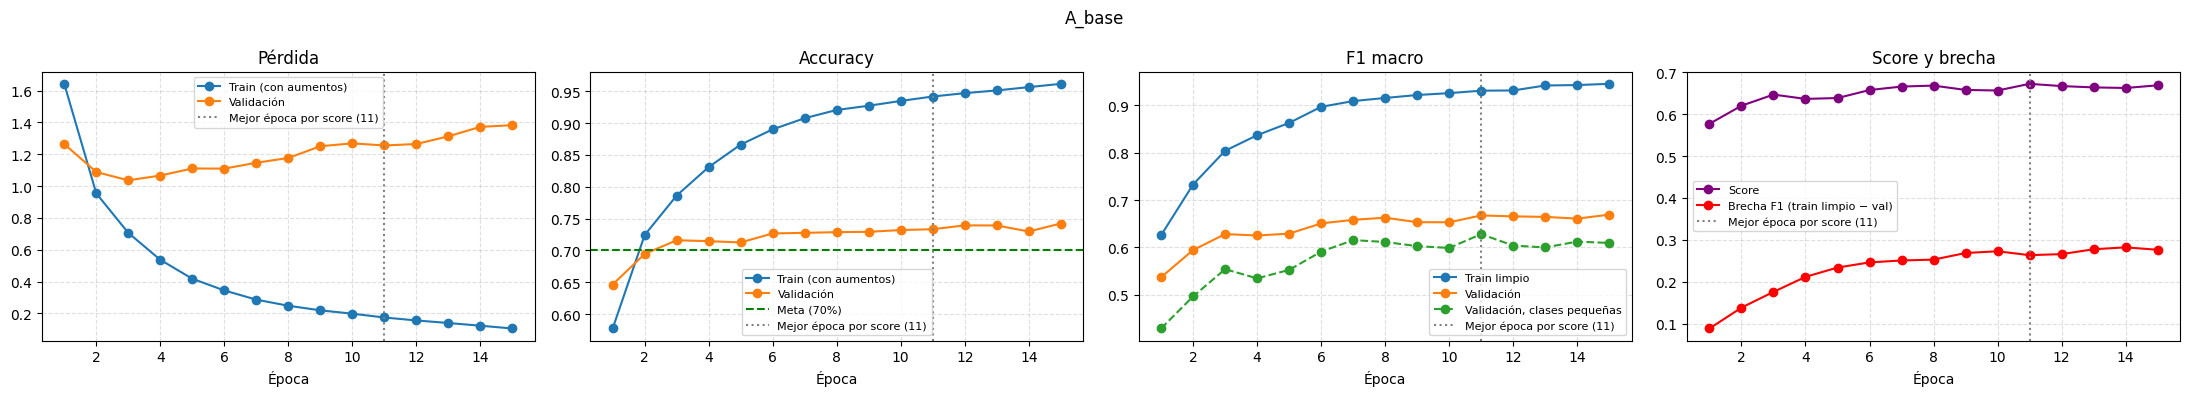

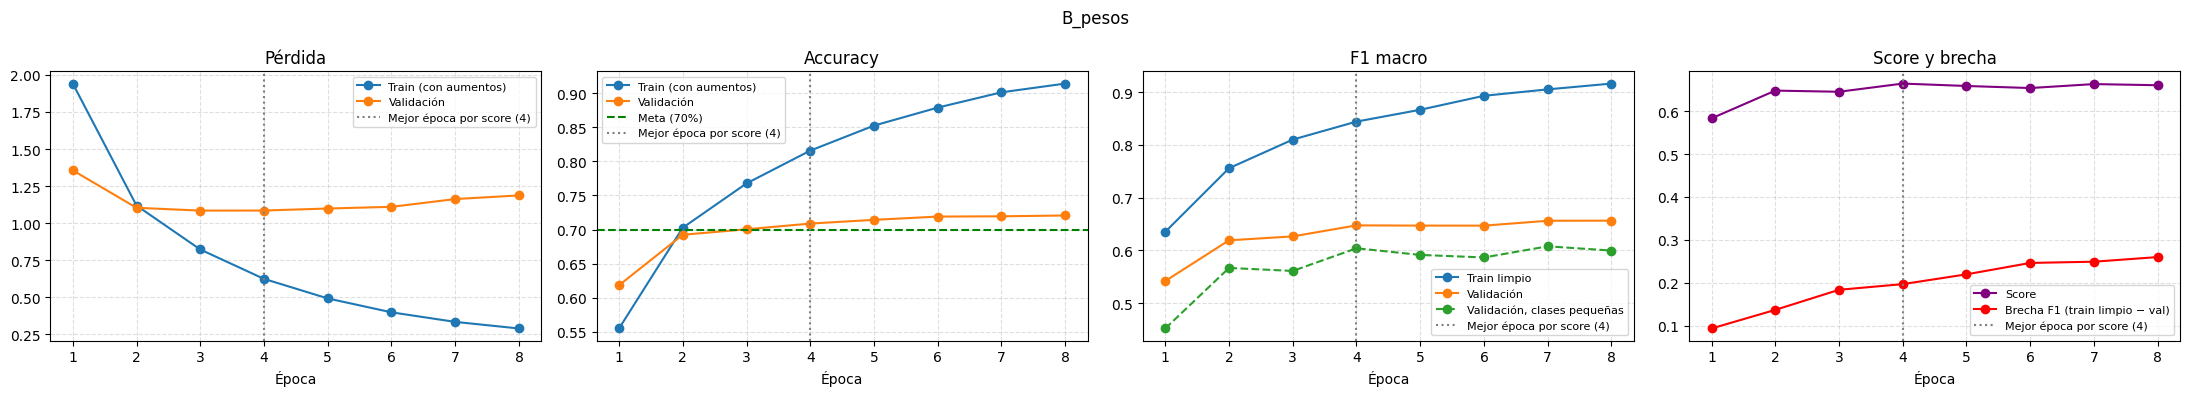

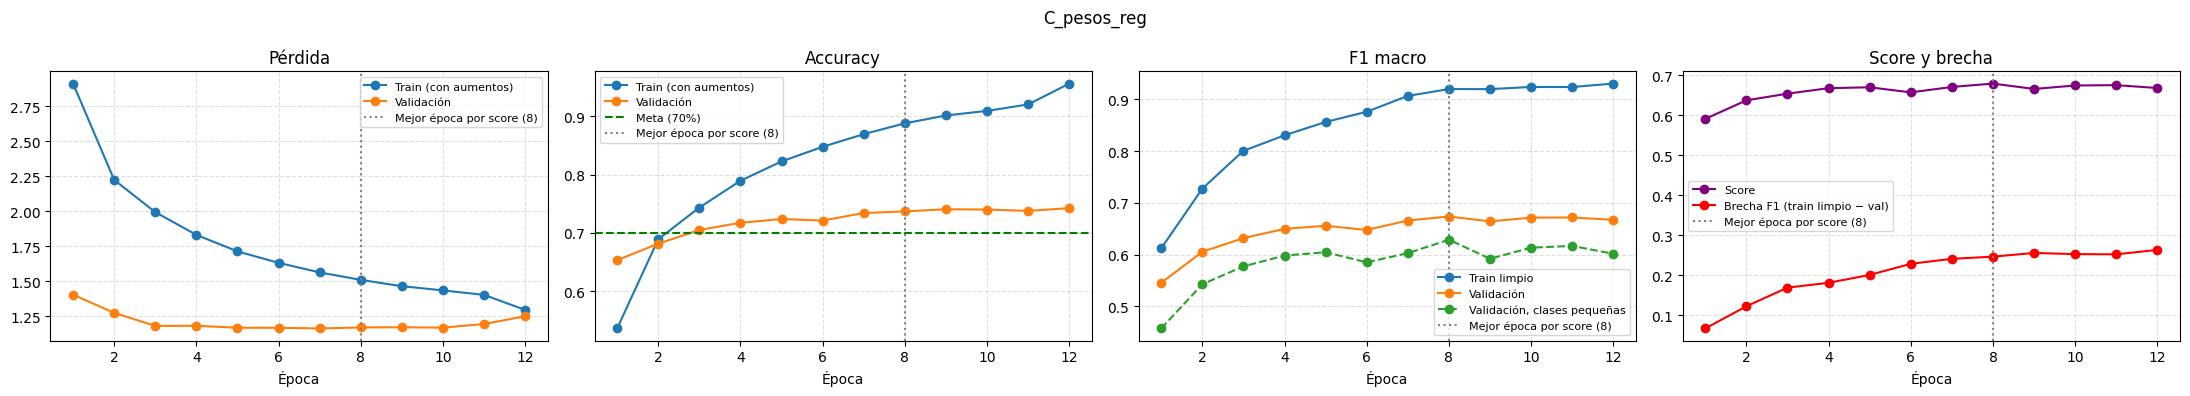

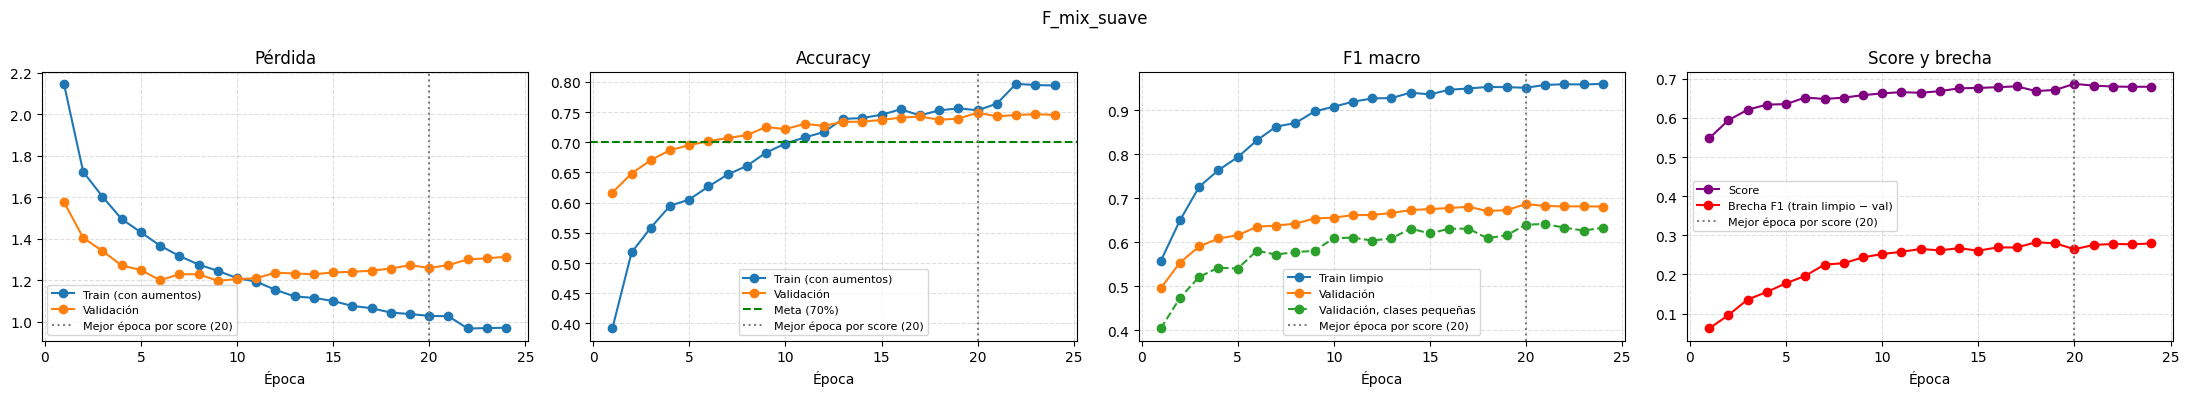

In [40]:
import os
import torch

# 1. Asegurar que cargamos los historiales de los archivos guardados en Drive
for nombre in ["A_base", "B_pesos", "C_pesos_reg", "F_mix_suave", "G_cnn_scratch"]:
    last_path = f"{CKPT_DIR}/{nombre}_last.pth"
    if os.path.exists(last_path):
        try:
            checkpoint = torch.load(last_path, map_location="cpu", weights_only=False)
            if "history" in checkpoint:
                histories[nombre] = checkpoint["history"]
                print(f"Historial de '{nombre}' cargado correctamente ({len(checkpoint['history']['val_f1'])} épocas).")
        except Exception as e:
            print(f"No se pudo cargar el historial de {nombre}: {e}")

# 2. Volver a graficar todos los experimentos disponibles (incluyendo G_cnn_scratch si tiene datos)
for nombre, h in histories.items():
    if len(h.get("val_f1", [])) > 0:
        plot_history(h, nombre)
    else:
        print(f"El experimento '{nombre}' no tiene épocas registradas para graficar.")

## 8. Resumen de experimentos y selección del modelo
La tabla muestra, para cada experimento, la época con mejor **score** y, a modo de comparación, la época con mejor F1 puro. La segunda tabla recalcula el ganador con **distintos pesos** a partir de los mismos historiales (sin reentrenar). Si el ganador casi no cambia entre escenarios, la elección es robusta; si cambia, hay que decirlo en el reporte.

Esta segunda tabla solo compara rankings: el checkpoint guardado de cada experimento corresponde a los pesos principales.

In [41]:
def resumen_experimentos(histories):
    filas = []
    for nombre, h in histories.items():
        i = int(np.argmax(h["score"]))
        j = int(np.argmax(h["val_f1"]))
        filas.append(dict(
            experimento=nombre, epocas_corridas=len(h["val_f1"]),
            mejor_epoca=i + 1, score=round(h["score"][i], 4),
            val_f1=round(h["val_f1"][i], 4), val_f1_cola=round(h["val_f1_cola"][i], 4),
            brecha_f1=round(h["brecha"][i], 4), val_acc=round(h["val_acc"][i], 4),
            val_loss=round(h["val_loss"][i], 4),
            mejor_epoca_f1_puro=j + 1, val_f1_max=round(h["val_f1"][j], 4),
        ))
    return pd.DataFrame(filas).set_index("experimento")


ESCENARIOS = {
    "principal (0.70 / 0.15 / 0.15)": (0.70, 0.15, 0.15),
    "solo F1 de validación":          (1.00, 0.00, 0.00),
    "más peso a la brecha":           (0.60, 0.15, 0.25),
    "más peso a clases pequeñas":     (0.55, 0.30, 0.15),
    "sin clases pequeñas":            (0.80, 0.00, 0.20),
}

def tabla_sensibilidad(histories, escenarios=ESCENARIOS):
    filas = {}
    for esc, w in escenarios.items():
        fila = {}
        for nombre, h in histories.items():
            s = (w[0] * np.array(h["val_f1"]) + w[1] * np.array(h["val_f1_cola"])
                 + w[2] * (1.0 - np.array(h["brecha"])))
            fila[nombre] = round(float(s.max()), 4)
        fila["GANADOR"] = max((k for k in fila), key=lambda k: fila[k])
        filas[esc] = fila
    return pd.DataFrame(filas).T


resumen = resumen_experimentos(histories)
display(resumen)
mejor_exp = resumen["score"].idxmax()
print("Mejor experimento según el score:", mejor_exp)
print("\nSensibilidad a los pesos del score:")
display(tabla_sensibilidad(histories))

,epocas_corridas,mejor_epoca,score,val_f1,val_f1_cola,brecha_f1,val_acc,val_loss,mejor_epoca_f1_puro,val_f1_max
experimento,,,,,,,,,,
D_resnet50,25,23,0.6167,0.5835,0.5150,0.1265,0.6697,1.3579,25,0.5837
G_cnn_scratch,25,25,0.4484,0.3784,0.3274,0.1042,0.4523,2.2770,25,0.3784
A_base,15,11,0.6720,0.6677,0.6281,0.2636,0.7334,1.2554,15,0.6693
B_pesos,8,4,0.6644,0.6475,0.6042,0.1967,0.7087,1.0846,8,0.6565
C_pesos_reg,12,8,0.6790,0.6737,0.6289,0.2461,0.7367,1.1718,8,0.6737
F_mix_suave,24,20,0.6873,0.6870,0.6402,0.2646,0.7489,1.2588,20,0.6870


Mejor experimento según el score: F_mix_suave

Sensibilidad a los pesos del score:


,D_resnet50,G_cnn_scratch,A_base,B_pesos,C_pesos_reg,F_mix_suave,GANADOR
principal (0.70 / 0.15 / 0.15),0.6167,0.4484,0.672,0.6644,0.679,0.6873,F_mix_suave
solo F1 de validación,0.5837,0.3784,0.6693,0.6565,0.6737,0.687,F_mix_suave
más peso a la brecha,0.6457,0.5001,0.6789,0.68,0.687,0.6921,F_mix_suave
más peso a clases pequeñas,0.6065,0.4407,0.6661,0.6579,0.6723,0.6802,F_mix_suave
sin clases pequeñas,0.6415,0.4819,0.6814,0.6787,0.6897,0.6967,F_mix_suave


## 9. Evaluación en test con el mejor modelo
El test se usa **una sola vez**, con el modelo elegido en la sección 8.

In [42]:
ckpt = torch.load(f"{CKPT_DIR}/{mejor_exp}_best.pth", map_location=device, weights_only=False)
cfg_b = ckpt["cfg"]
best_model = build_model(cfg_b["model_name"], cfg_b["drop_path"], pretrained=False).to(device)
best_model.load_state_dict(ckpt["state_dict"])
best_model.eval()
print(f"Modelo cargado: {mejor_exp} (época {ckpt['epoch']}, F1 val={ckpt['val_f1']:.4f}, score={ckpt['score']:.4f})")

test_results = evaluate(best_model, test_loader)
print(f"\nTest -> Acc: {test_results['acc']:.4f} | F1 macro: {test_results['f1']:.4f}")

Modelo cargado: F_mix_suave (época 20, F1 val=0.6870, score=0.6873)

Test -> Acc: 0.7416 | F1 macro: 0.6788


### Métricas por clase

In [43]:
prec, rec, f1_per, sup = precision_recall_fscore_support(
    test_results["labels"], test_results["preds"], labels=range(NUM_CLASSES), zero_division=0)

df_metrics = pd.DataFrame({
    "clase": [nombres[i] for i in range(NUM_CLASSES)],
    "precision": np.round(prec, 3), "recall": np.round(rec, 3), "f1": np.round(f1_per, 3),
    "n_test": sup, "n_train": [counts[i] for i in range(NUM_CLASSES)],
}).set_index("clase").sort_values("f1")

print("10 clases con peor F1:")
display(df_metrics.head(10))
print("\n10 clases con mejor F1:")
display(df_metrics.tail(10))

10 clases con peor F1:


,precision,recall,f1,n_test,n_train
clase,,,,,
therioaphis maculata Buckton,0.283,0.218,0.246,78,156
green bug,0.293,0.276,0.284,98,195
large cutworm,0.312,0.264,0.286,148,294
english grain aphid,0.399,0.340,0.367,197,392
rice shell pest,0.488,0.325,0.390,123,245
bird cherry-oataphid,0.397,0.437,0.416,213,424
yellow cutworm,0.471,0.389,0.426,144,287
Thrips,0.437,0.436,0.436,264,527
flax budworm,0.504,0.391,0.440,320,639



10 clases con mejor F1:


,precision,recall,f1,n_test,n_train
clase,,,,,
Brevipoalpus lewisi McGregor,0.913,0.875,0.894,24,47
Aleurocanthus spiniferus,0.869,0.928,0.898,208,414
Potosiabre vitarsis,0.908,0.924,0.915,170,339
Locustoidea,0.904,0.940,0.922,419,836
Limacodidae,0.928,0.924,0.926,421,840
wheat blossom midge,0.888,0.979,0.932,146,291
mole cricket,0.940,0.976,0.957,495,989
Pieris canidia,0.964,0.950,0.957,141,279
Papilio xuthus,0.950,0.978,0.964,135,269


Spearman n_train vs F1: rho=0.27, p=0.0068
F1 medio de las 35 clases con <200 imágenes de train: 0.628
F1 medio del resto (67 clases): 0.705


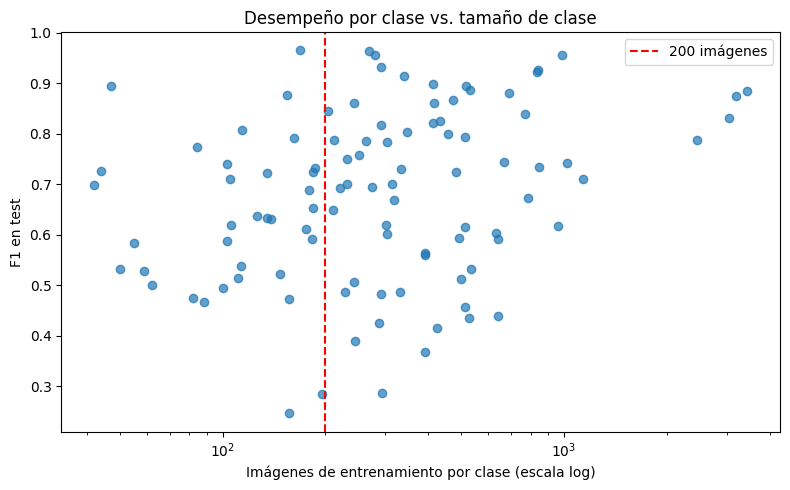

In [44]:
# Correlación entre tamaño de clase y desempeño
from scipy.stats import spearmanr
rho, p = spearmanr(df_metrics["n_train"], df_metrics["f1"])
print(f"Spearman n_train vs F1: rho={rho:.2f}, p={p:.3g}")

pocas = df_metrics["n_train"] < CFG["tail_umbral"]
print(f"F1 medio de las {pocas.sum()} clases con <{CFG['tail_umbral']} imágenes de train: {df_metrics.loc[pocas, 'f1'].mean():.3f}")
print(f"F1 medio del resto ({(~pocas).sum()} clases): {df_metrics.loc[~pocas, 'f1'].mean():.3f}")

plt.figure(figsize=(8, 5))
plt.scatter(df_metrics["n_train"], df_metrics["f1"], alpha=0.7)
plt.xscale("log")
plt.axvline(CFG["tail_umbral"], color="r", ls="--", label=f"{CFG['tail_umbral']} imágenes")
plt.xlabel("Imágenes de entrenamiento por clase (escala log)")
plt.ylabel("F1 en test")
plt.title("Desempeño por clase vs. tamaño de clase")
plt.legend(); plt.tight_layout(); plt.show()

### Matriz de confusión

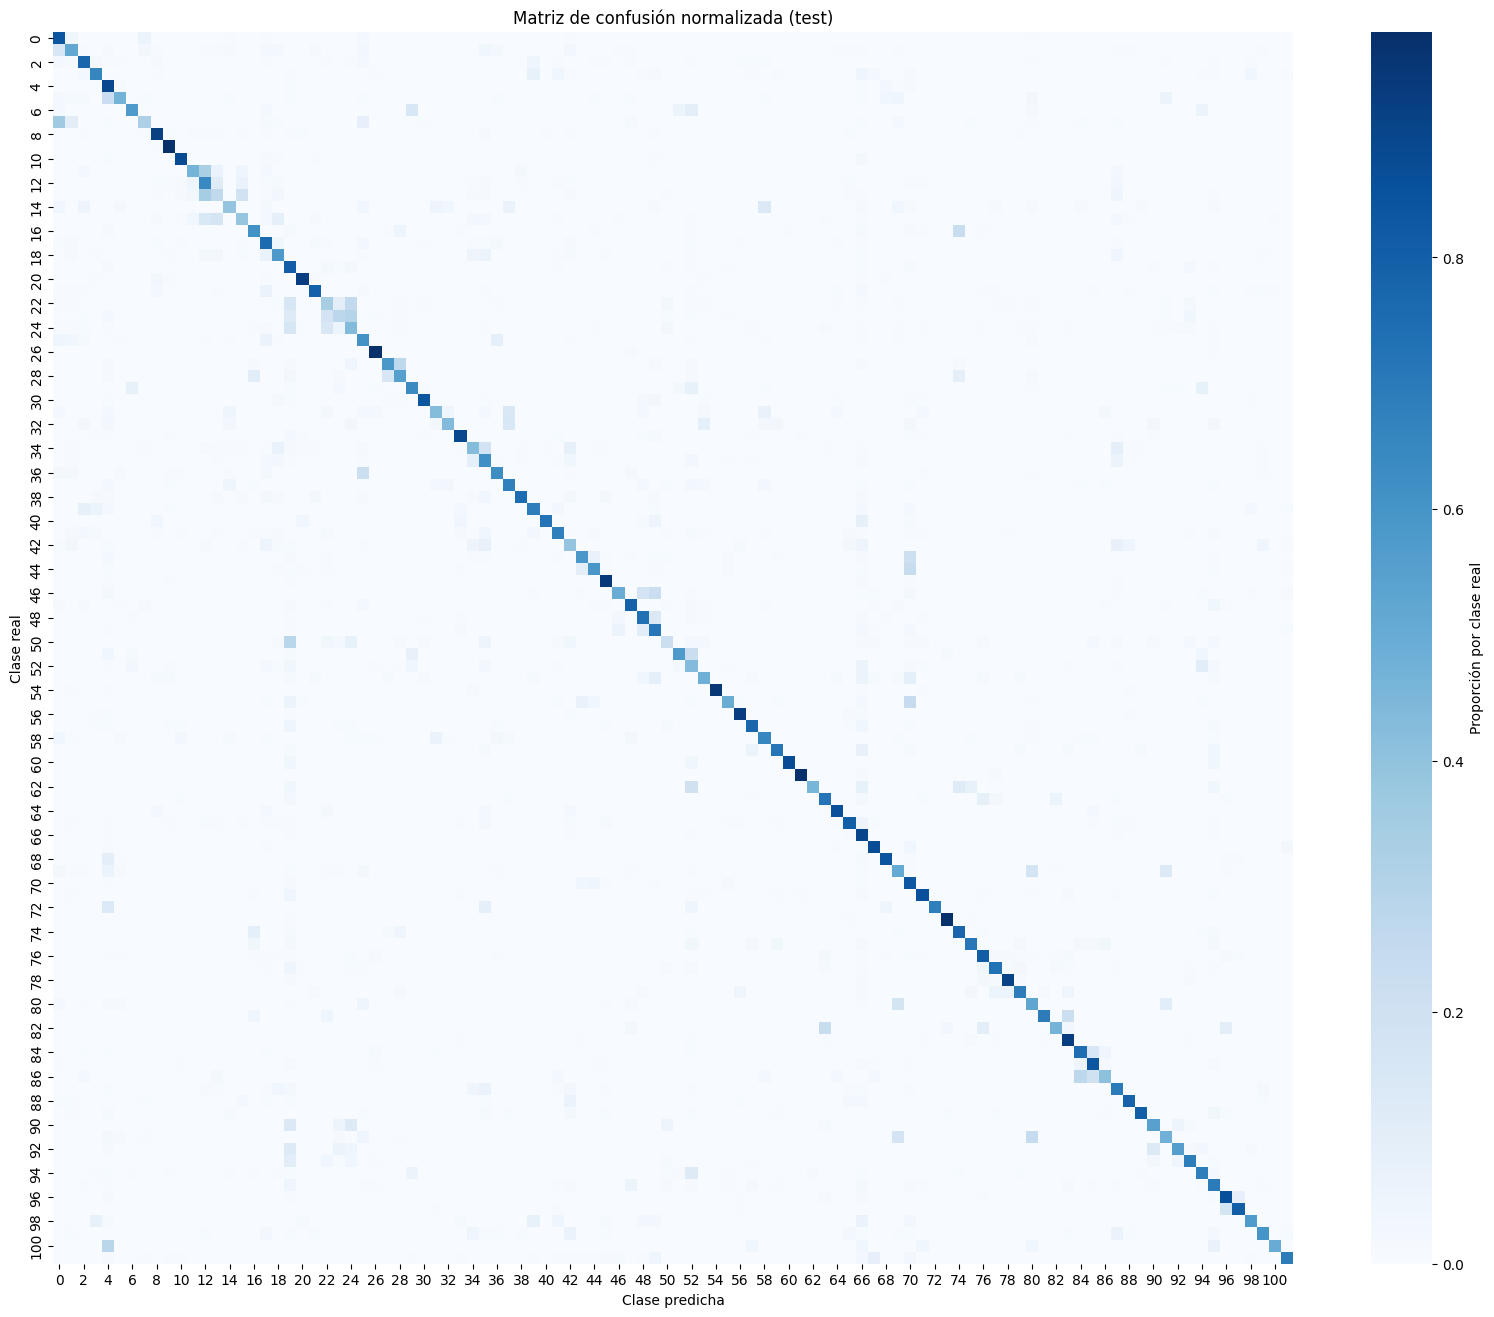

,real,predicha,veces,pct_de_la_clase
0,Miridae,tarnished plant bug,65,4.3
1,blister beetle,legume blister beetle,61,10.7
2,legume blister beetle,blister beetle,59,13.9
3,tarnished plant bug,Miridae,58,23.6
4,Miridae,alfalfa plant bug,54,3.5
5,english grain aphid,bird cherry-oataphid,51,25.9
6,large cutworm,black cutworm,51,34.5
7,cabbage army worm,beet army worm,48,18.7
8,white backed plant hopper,brown plant hopper,48,17.9
9,Cicadellidae,Cicadella viridis,48,2.8


In [45]:
cm = confusion_matrix(test_results["labels"], test_results["preds"], labels=range(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

plt.figure(figsize=(20, 16))
sns.heatmap(cm_norm, cmap="Blues", cbar_kws={"label": "Proporción por clase real"})
plt.title("Matriz de confusión normalizada (test)")
plt.xlabel("Clase predicha"); plt.ylabel("Clase real")
plt.show()

# Parejas de clases más confundidas (fuera de la diagonal)
off = cm.copy()
np.fill_diagonal(off, 0)
idx = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1], off.shape))[0][:10]
filas = [dict(real=nombres[i], predicha=nombres[j], veces=int(off[i, j]),
              pct_de_la_clase=round(100 * off[i, j] / cm[i].sum(), 1)) for i, j in idx]
display(pd.DataFrame(filas))

## 10. Viabilidad y plan de trabajo



### Actividades

| Semana | Actividades | Entregable |
|---|---|---|
| **1. Datos y base** | Descargar IP102 y cargarlo con `ImageFolder`. Explorar el conjunto: ejemplos por clase, desbalance, imágenes corruptas, duplicados y fuga de datos entre particiones, dimensiones y ejemplos con etiquetas. Limpiar los duplicados detectados. Construir el pipeline de datos (transformaciones, aumento de datos, `DataLoader`) y las funciones de entrenamiento, validación y checkpoints. | Notebook reproducible con EDA completo y pipeline funcional. |
| **2. Modelos y experimentos** | Entrenar ConvNeXt-Tiny con y sin pesos de clase, añadir *label smoothing* y *drop path*. Entrenar ResNet-50 como referencia. Comparar F1 macro en validación y test, y analizar curvas de entrenamiento. | Tabla comparativa de experimentos y gráficas de entrenamiento. |
| **3. Análisis y reporte** | Matriz de confusión, métricas por clase, análisis de clases con peor desempeño y de pares confundidos. Correlación entre tamaño de clase y F1. Conclusiones y recomendaciones. | Informe final con conclusiones y recomendaciones. |

### Recursos
- **Hardware:** GPU de Google Colab (CUDA) con precisión mixta para acelerar el entrenamiento.
- **Software:** PyTorch, torchvision, `timm` (modelos preentrenados), scikit-learn (métricas), matplotlib y seaborn (gráficas), kagglehub (descarga).
- **Datos:** IP102, ~75,000 imágenes (~3 GB), de acceso público en Kaggle.
- **Almacenamiento:** disco de Colab para los checkpoints, de modo que el entrenamiento pueda reanudarse si la sesión se interrumpe.

### Dificultades previstas y mitigación
- **Desbalance fuerte (~81:1):** se usan pesos de clase (raíz del inverso), *label smoothing* y *drop path* para regularizar.
- **Clases con pocas imágenes:** se analiza el desempeño por clase y se identifica si se necesitan más datos o estrategias específicas.
- **Clases visualmente similares:** se analiza la matriz de confusión para identificar pares confundidos y proponer mejoras (más aumento de datos, fine-tuning más largo, etc.).
- **Tiempo de entrenamiento limitado:** se usa un modelo de tamaño moderado (ConvNeXt-Tiny) y precisión mixta para acelerar.